> ### Import Library

In [1]:
# import library pandas untuk pemrosesan tabel data
import pandas as pd
# import library numpy untuk komputasi numerik dan array
import numpy as np
# import library matplotlib untuk pengaturan layout kanvas grafik
import matplotlib.pyplot as plt
# import library seaborn untuk visualisasi distribusi data klinis
import seaborn as sns

# atur agar seluruh kolom ditampilkan tanpa dipotong titik-titik
pd.set_option("display.max_columns", None)
# atur batas tampilan baris maksimal 100 agar colab tetap ringan
pd.set_option("display.max_rows", 100)


In [2]:
# from google.colab import drive
# drive.mount('/content/drive')

In [3]:
data = pd.read_csv("idn_weather_daily.csv")

In [5]:
# 1. Filter DataFrame berdasarkan provinsi
jawa_tengah_df = data[data["province"] == "Jawa Tengah"]

# 2. Ambil list unik kotanya
kota_jateng = jawa_tengah_df["city"].unique().tolist()

print(kota_jateng)

['Semarang']


> ### Data Understanding

In [4]:
data.head()

,city,province,island,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration
0,Ambon,Maluku,Maluku,2000-01-01,55.0,29.1,25.3,27.5,1.7,2.0,12.2,19.4,19.23,4.11
1,Ambon,Maluku,Maluku,2000-01-02,53.0,28.5,25.9,27.1,2.6,9.0,11.3,24.1,22.54,4.55
2,Ambon,Maluku,Maluku,2000-01-03,61.0,28.5,24.3,26.4,8.1,14.0,11.0,19.1,22.15,4.48
3,Ambon,Maluku,Maluku,2000-01-04,53.0,28.3,25.8,26.9,3.3,10.0,14.9,26.3,22.40,4.44
4,Ambon,Maluku,Maluku,2000-01-05,55.0,28.3,25.9,26.9,4.5,11.0,11.7,21.2,22.05,4.46


In [5]:
data.shape

(303645, 14)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303645 entries, 0 to 303644
Data columns (total 14 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   city                        303645 non-null  object 
 1   province                    303645 non-null  object 
 2   island                      303645 non-null  object 
 3   date                        303645 non-null  object 
 4   weather_code                303645 non-null  float64
 5   temperature_2m_max          303645 non-null  float64
 6   temperature_2m_min          303645 non-null  float64
 7   temperature_2m_mean         303645 non-null  float64
 8   precipitation_sum           303645 non-null  float64
 9   precipitation_hours         303645 non-null  float64
 10  wind_speed_10m_max          303645 non-null  float64
 11  wind_gusts_10m_max          303645 non-null  float64
 12  shortwave_radiation_sum     303645 non-null  float64
 13  et0_fao_evapot

We gonna change 'date' data type into datetime later

In [7]:
data.describe()

,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration
count,303645.000000,303645.000000,303645.000000,303645.000000,303645.00000,303645.000000,303645.000000,303645.000000,303645.000000,303645.000000
mean,51.363731,29.510108,23.672257,26.143575,7.30874,8.750511,11.702967,28.788240,18.288555,3.796256
std,19.125501,1.793365,1.434661,1.243336,9.52737,6.362276,4.924546,7.879503,4.112996,0.937060
min,0.000000,21.100000,13.900000,19.100000,0.00000,0.000000,2.600000,11.200000,0.660000,0.350000
25%,51.000000,28.300000,23.100000,25.500000,0.80000,4.000000,8.200000,23.000000,15.900000,3.210000
50%,61.000000,29.500000,23.800000,26.200000,4.30000,8.000000,10.600000,27.400000,18.780000,3.830000
75%,63.000000,30.600000,24.500000,26.900000,10.70000,13.000000,14.100000,32.800000,21.160000,4.400000
max,65.000000,43.400000,28.700000,31.300000,308.80000,24.000000,58.600000,107.600000,29.100000,8.000000


Temperature with 43.4°C is quite sus, we gonna check it later

- How many province here?

In [8]:
print(data["province"].nunique())
print(data["province"].value_counts())

29
province
Jawa Timur             19590
Kalimantan Timur       19590
Sulawesi Utara          9795
Maluku Utara            9795
Papua Barat Daya        9795
Banten                  9795
Jawa Tengah             9795
Kalimantan Barat        9795
Riau                    9795
Sulawesi Tengah         9795
Sumatera Selatan        9795
Kalimantan Tengah       9795
Sumatera Barat          9795
Sumatera Utara          9795
Nusa Tenggara Barat     9795
Maluku                  9795
Sulawesi Selatan        9795
Nusa Tenggara Timur     9795
Sulawesi Tenggara       9795
Papua                   9795
Jambi                   9795
DKI Jakarta             9795
Bali                    9795
Kepulauan Riau          9795
Kalimantan Selatan      9795
Jawa Barat              9795
Lampung                 9795
Aceh                    9795
DI Yogyakarta           9795
Name: count, dtype: int64


There area 29 province in our dataset

> ### Data Cleaning

- Check Missing Values

In [9]:
data.isnull().sum()

city                          0
province                      0
island                        0
date                          0
weather_code                  0
temperature_2m_max            0
temperature_2m_min            0
temperature_2m_mean           0
precipitation_sum             0
precipitation_hours           0
wind_speed_10m_max            0
wind_gusts_10m_max            0
shortwave_radiation_sum       0
et0_fao_evapotranspiration    0
dtype: int64

The dataset are safe from missing values

In [10]:
data.duplicated().sum()

0

The dataset are safe from duplicated data

- Change date data type

In [11]:
data['date'] = pd.to_datetime(data['date']).dt.date

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303645 entries, 0 to 303644
Data columns (total 14 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   city                        303645 non-null  object 
 1   province                    303645 non-null  object 
 2   island                      303645 non-null  object 
 3   date                        303645 non-null  object 
 4   weather_code                303645 non-null  float64
 5   temperature_2m_max          303645 non-null  float64
 6   temperature_2m_min          303645 non-null  float64
 7   temperature_2m_mean         303645 non-null  float64
 8   precipitation_sum           303645 non-null  float64
 9   precipitation_hours         303645 non-null  float64
 10  wind_speed_10m_max          303645 non-null  float64
 11  wind_gusts_10m_max          303645 non-null  float64
 12  shortwave_radiation_sum     303645 non-null  float64
 13  et0_fao_evapot

- Check Outliers

Columns to plot (9):
  - temperature_2m_max
  - temperature_2m_min
  - temperature_2m_mean
  - precipitation_sum
  - precipitation_hours
  - wind_speed_10m_max
  - wind_gusts_10m_max
  - shortwave_radiation_sum
  - et0_fao_evapotranspiration

Processing: temperature_2m_max


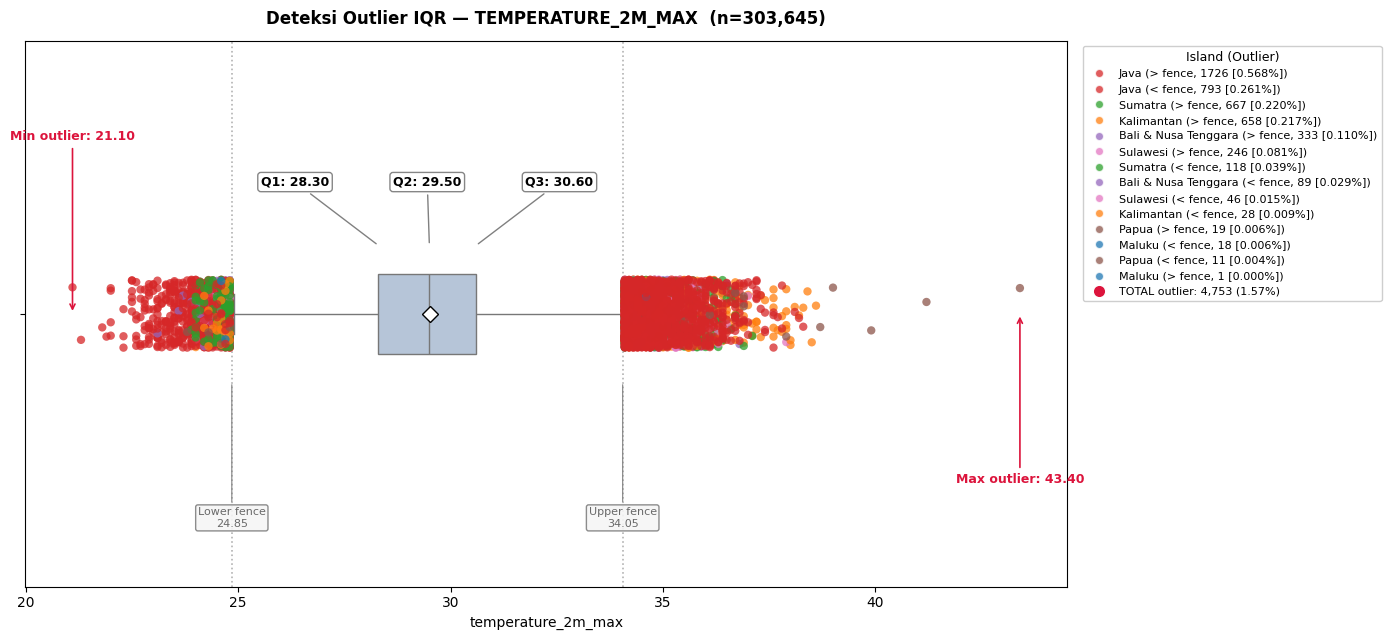

Column      : temperature_2m_max
n valid     : 303,645
Q1 / Q2 / Q3: 28.30 / 29.50 / 30.60
IQR         : 2.30
Fence       : [24.85, 34.05]
Outlier     : 4,753 (1.57%)

Processing: temperature_2m_min


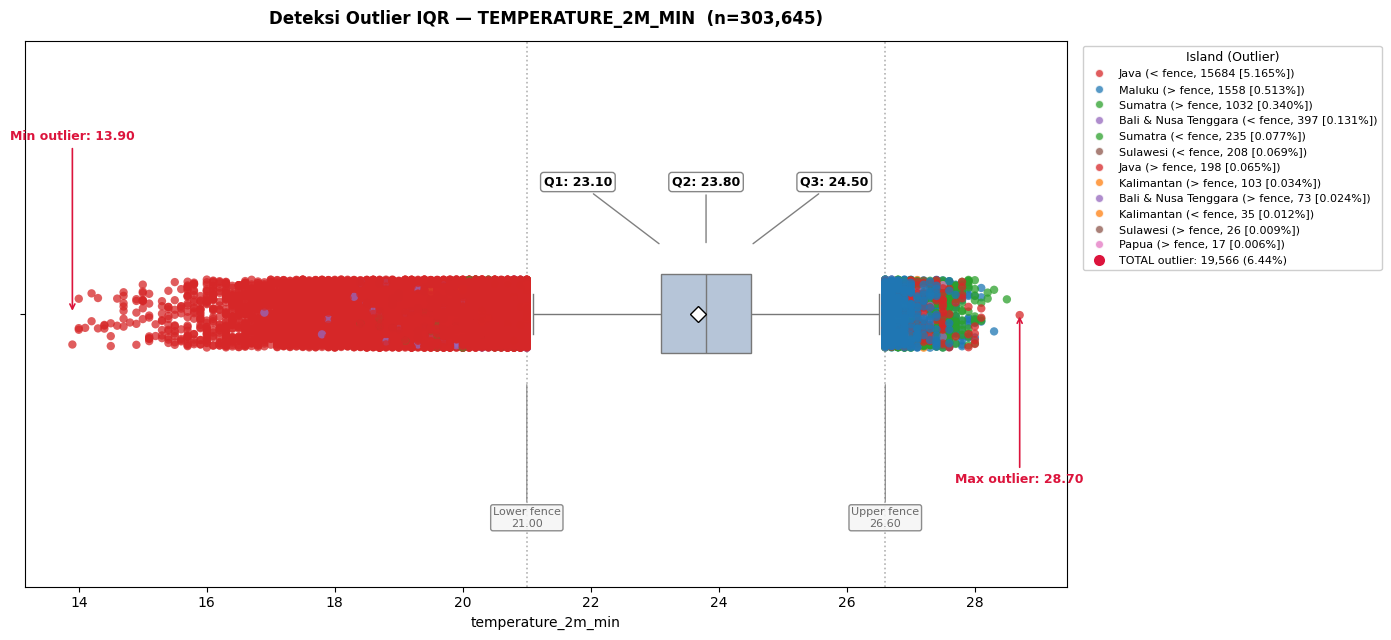

Column      : temperature_2m_min
n valid     : 303,645
Q1 / Q2 / Q3: 23.10 / 23.80 / 24.50
IQR         : 1.40
Fence       : [21.00, 26.60]
Outlier     : 19,566 (6.44%)

Processing: temperature_2m_mean


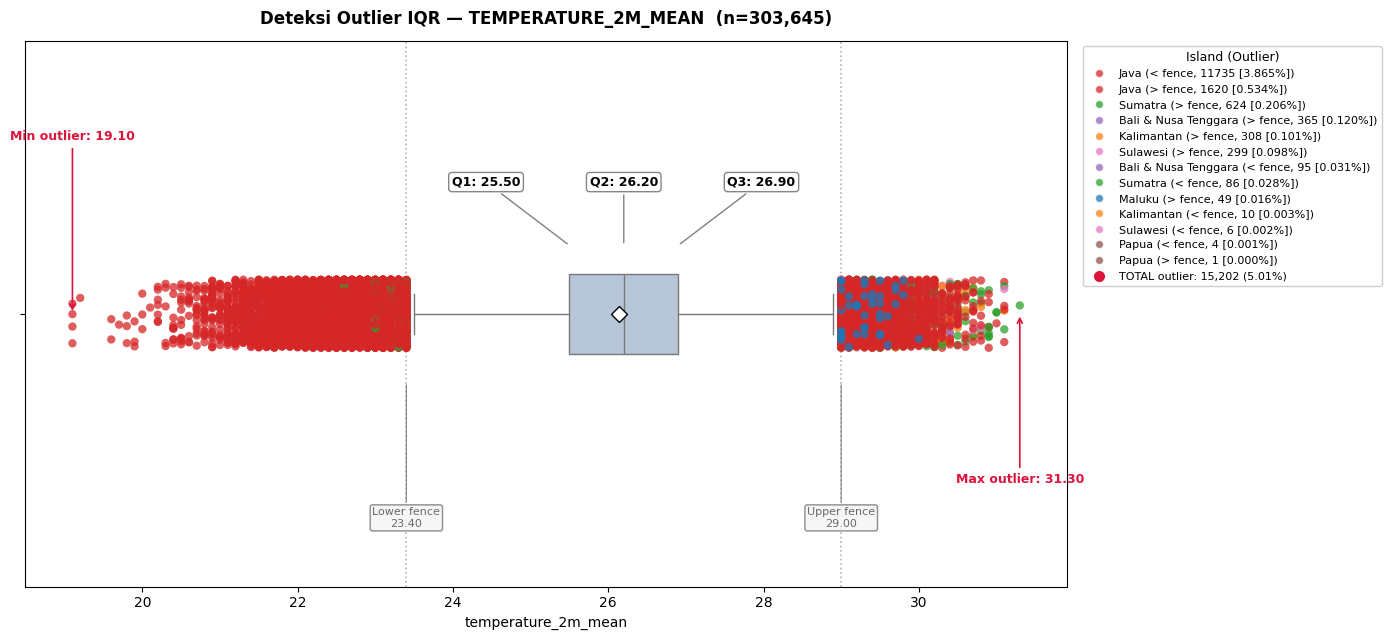

Column      : temperature_2m_mean
n valid     : 303,645
Q1 / Q2 / Q3: 25.50 / 26.20 / 26.90
IQR         : 1.40
Fence       : [23.40, 29.00]
Outlier     : 15,202 (5.01%)

Processing: precipitation_sum


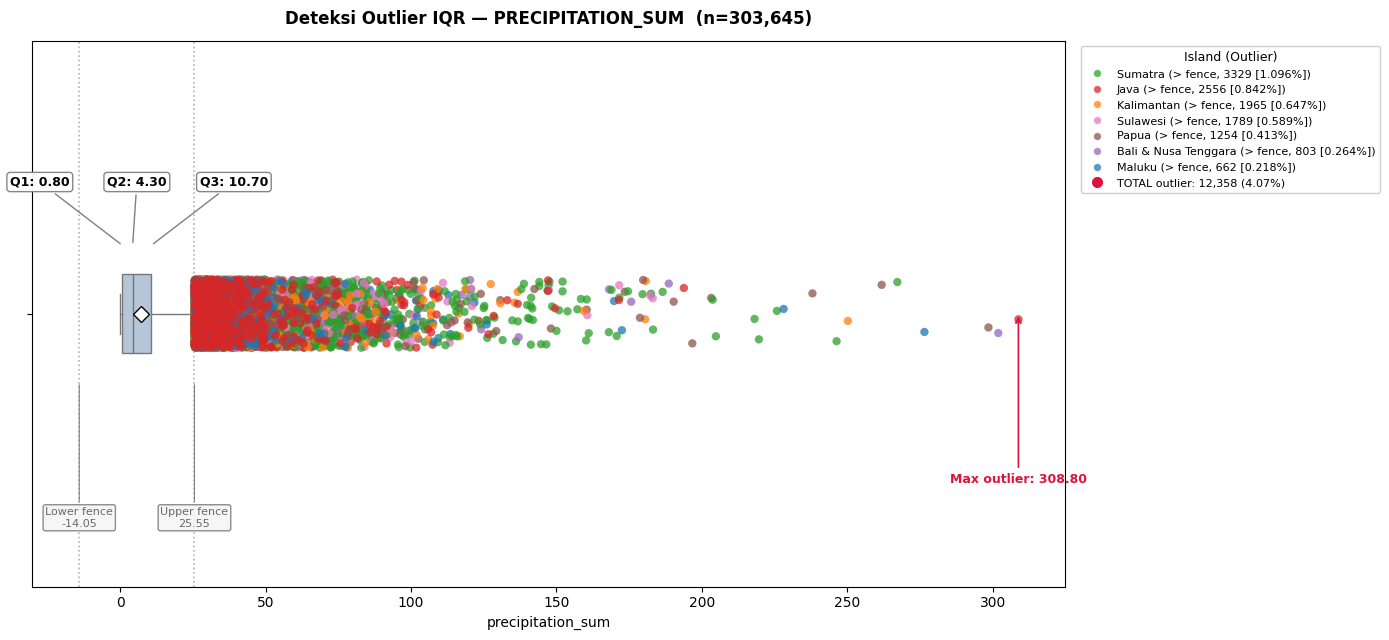

Column      : precipitation_sum
n valid     : 303,645
Q1 / Q2 / Q3: 0.80 / 4.30 / 10.70
IQR         : 9.90
Fence       : [-14.05, 25.55]
Outlier     : 12,358 (4.07%)

Processing: precipitation_hours


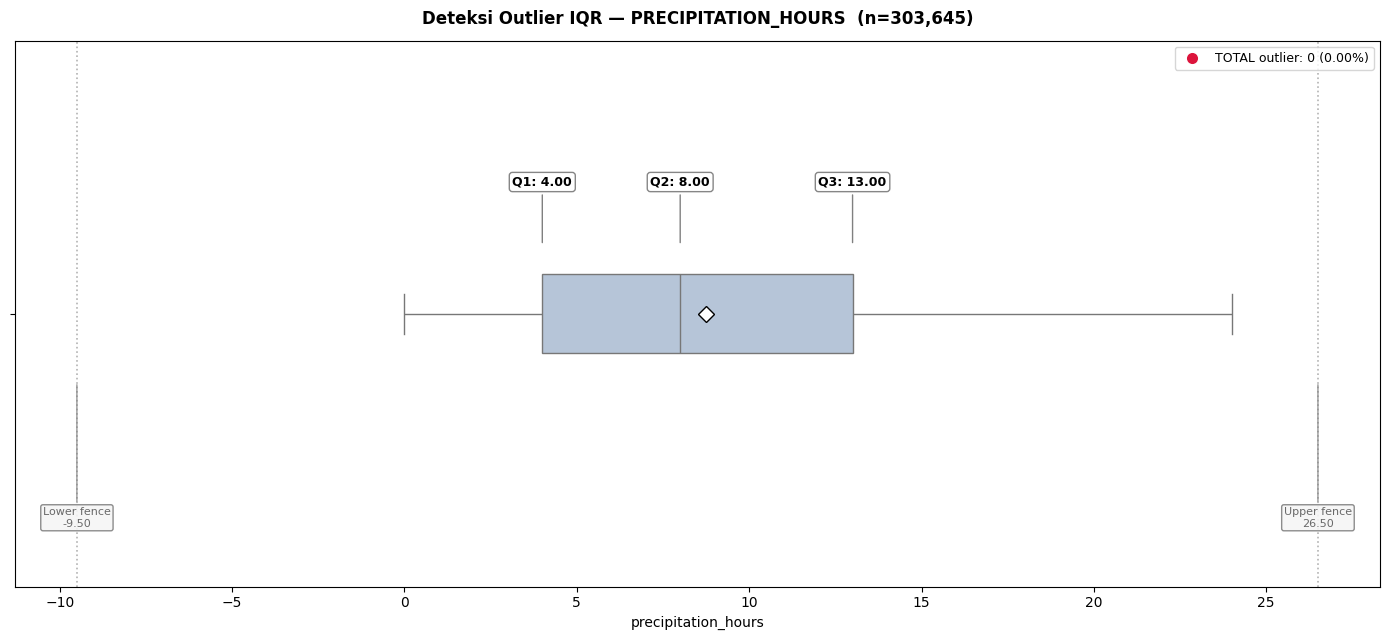

Column      : precipitation_hours
n valid     : 303,645
Q1 / Q2 / Q3: 4.00 / 8.00 / 13.00
IQR         : 9.00
Fence       : [-9.50, 26.50]
Outlier     : 0 (0.00%)

Processing: wind_speed_10m_max


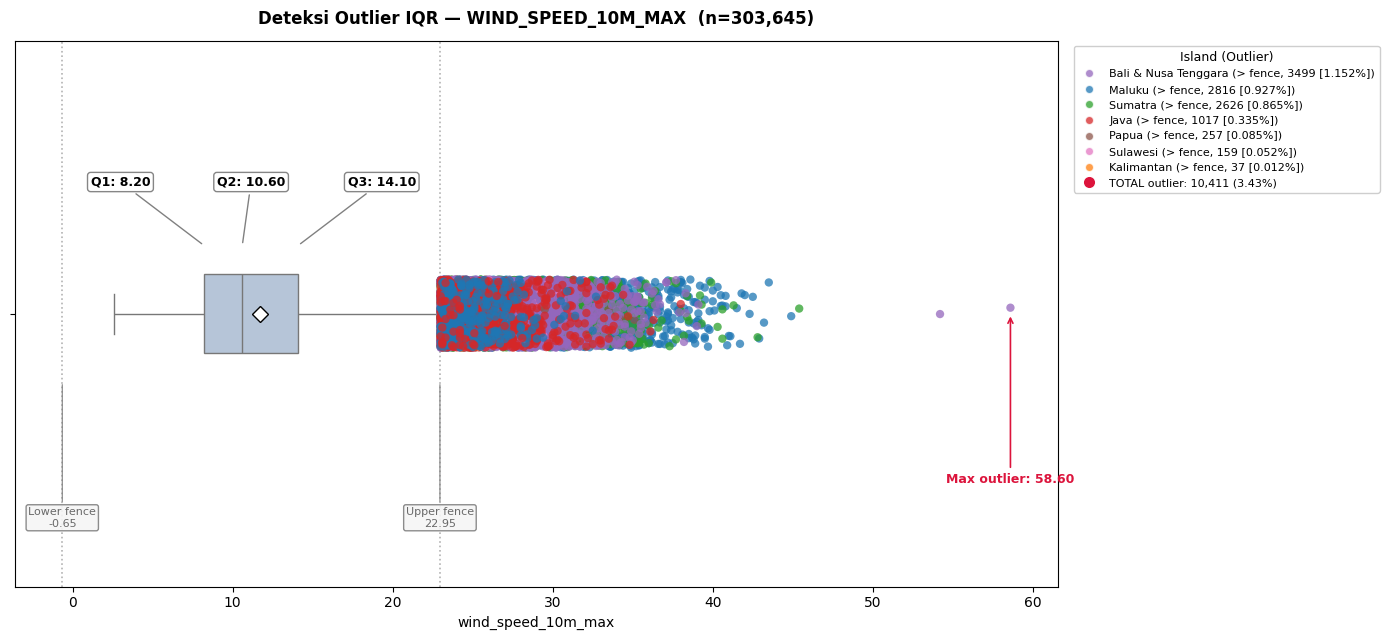

Column      : wind_speed_10m_max
n valid     : 303,645
Q1 / Q2 / Q3: 8.20 / 10.60 / 14.10
IQR         : 5.90
Fence       : [-0.65, 22.95]
Outlier     : 10,411 (3.43%)

Processing: wind_gusts_10m_max


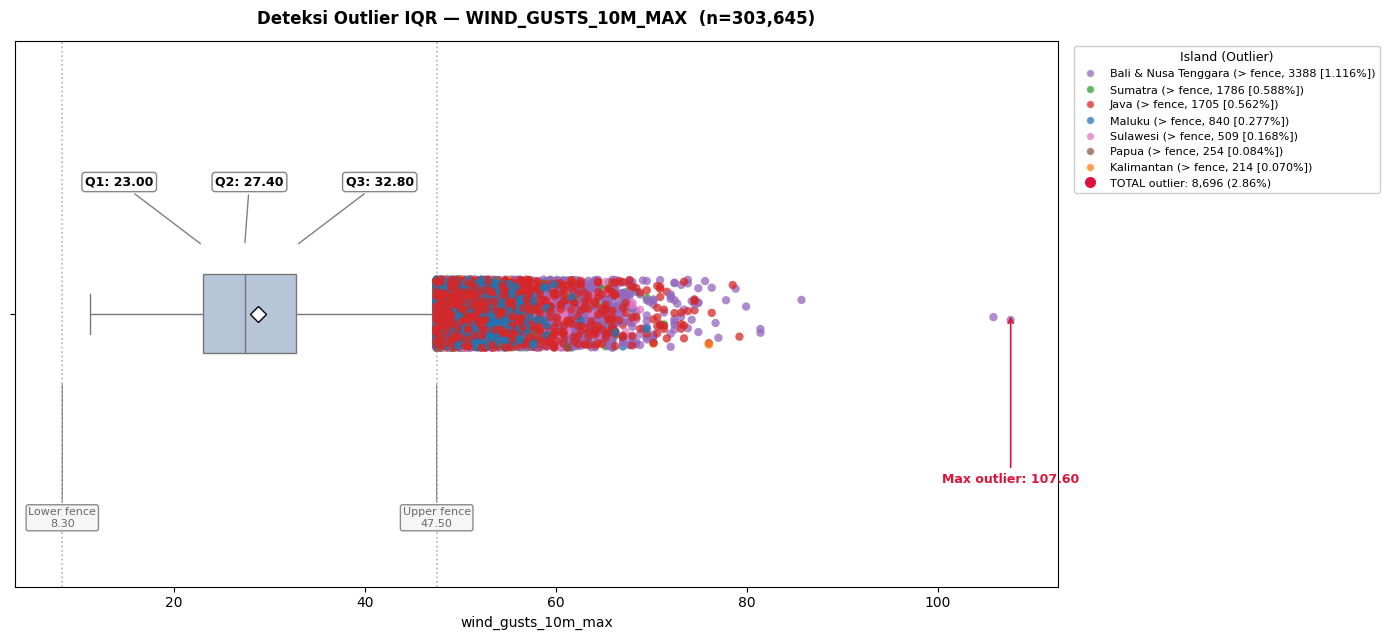

Column      : wind_gusts_10m_max
n valid     : 303,645
Q1 / Q2 / Q3: 23.00 / 27.40 / 32.80
IQR         : 9.80
Fence       : [8.30, 47.50]
Outlier     : 8,696 (2.86%)

Processing: shortwave_radiation_sum


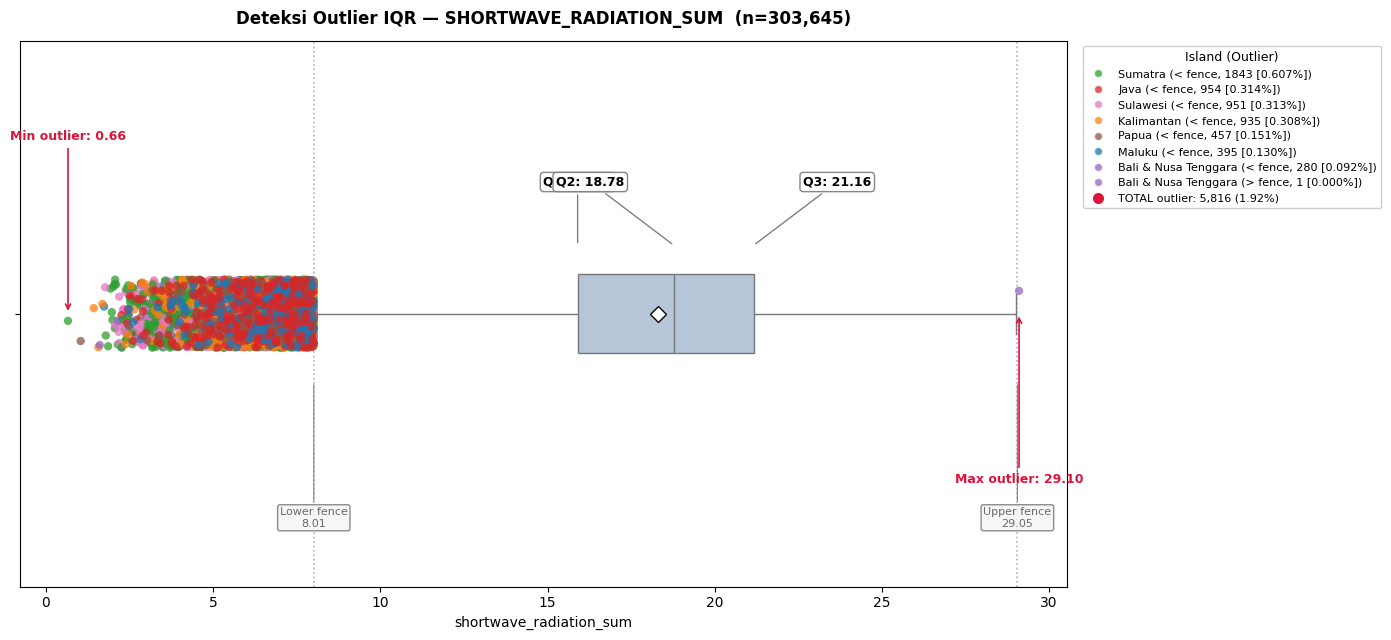

Column      : shortwave_radiation_sum
n valid     : 303,645
Q1 / Q2 / Q3: 15.90 / 18.78 / 21.16
IQR         : 5.26
Fence       : [8.01, 29.05]
Outlier     : 5,816 (1.92%)

Processing: et0_fao_evapotranspiration


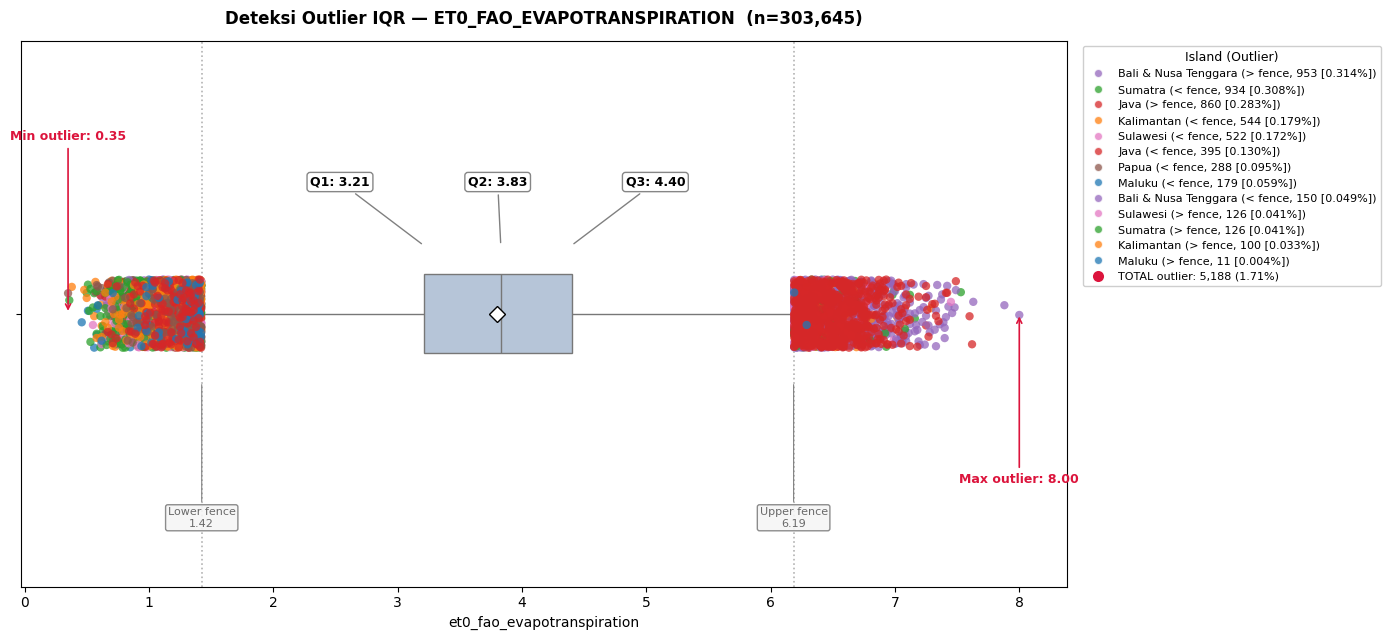

Column      : et0_fao_evapotranspiration
n valid     : 303,645
Q1 / Q2 / Q3: 3.21 / 3.83 / 4.40
IQR         : 1.19
Fence       : [1.42, 6.19]
Outlier     : 5,188 (1.71%)

Done. Saved to: Laporan_Outlier_Cuaca.pdf


In [13]:
from matplotlib.backends.backend_pdf import PdfPages

def plot_iqr_boxplot(df, col, group_col=None, palette='tab10', figsize=(14, 6.5), pdf=None):
    # determine columns to use, add group_col if provided
    cols = [col] + ([group_col] if group_col else [])

    # drop NaN on the main column
    sub = df[cols].dropna(subset=[col]).copy()

    # take the main column as a series
    s = sub[col]

    # compute Q1, Q2 (median), Q3
    q1 = s.quantile(0.25)
    q2 = s.quantile(0.50)
    q3 = s.quantile(0.75)

    # compute IQR
    iqr = q3 - q1

    # compute lower and upper fences
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    # flag rows that fall outside the fences
    mask = (s < lower_fence) | (s > upper_fence)

    # copy outlier rows into a new dataframe
    df_out = sub.loc[mask].copy()

    # add a column marking outlier position (Bawah / Atas)
    df_out['posisi'] = np.where(df_out[col] < lower_fence, 'Bawah', 'Atas')

    # count outliers and their percentage
    n_out = len(df_out)
    pct = (n_out / len(s) * 100) if len(s) > 0 else 0

    # create figure and axis
    fig, ax = plt.subplots(figsize=figsize)

    # draw the boxplot, hide default fliers so we can color them manually
    sns.boxplot(
        x=s, ax=ax, color='lightsteelblue', width=0.35,
        showfliers=False, showmeans=True,
        meanprops={"marker": "D", "markerfacecolor": "white",
                   "markeredgecolor": "black", "markersize": 8}
    )

    # draw vertical lines for lower and upper fences
    for v in (lower_fence, upper_fence):
        ax.axvline(v, color='gray', linestyle=':', alpha=0.6, lw=1.2)

    # plot outlier points if any exist
    if not df_out.empty:
        if group_col:
            sns.stripplot(
                data=df_out, x=col, hue=group_col, ax=ax,
                size=6, alpha=0.75, jitter=0.15, palette=palette,
                legend=False
            )
        else:
            ax.scatter(df_out[col], np.zeros(len(df_out)),
                       color='crimson', alpha=0.7, s=35, edgecolor='white')

    # text box style for Q1/Q2/Q3 annotations
    bbox = dict(boxstyle="round,pad=0.25", facecolor="white",
                edgecolor="gray", alpha=0.95)

    # arrow style for annotation connectors
    arrow = dict(arrowstyle="-", color="gray", lw=1)

    # get x-axis range to compute minimum gap between labels
    x_min, x_max = ax.get_xlim()
    min_gap = (x_max - x_min) * 0.08

    # initial text positions match the real values
    tx1, tx2, tx3 = q1, q2, q3

    # if Q1 and Q2 are too close, spread them apart
    if q2 - q1 < min_gap:
        tx1 = q1 - min_gap
        tx2 = q2 + min_gap

    # if Q2 and Q3 are too close, spread them apart as well
    if q3 - q2 < min_gap:
        tx3 = q3 + min_gap
        # if all three are packed together, put Q2 in the middle
        if q2 - q1 < min_gap:
            tx2 = (q1 + q3) / 2
        else:
            tx2 = q2 - min_gap

    # write Q1, Q2, Q3 annotations above the boxplot
    for label, val, tx in [('Q1', q1, tx1), ('Q2', q2, tx2), ('Q3', q3, tx3)]:
        ax.annotate(
            f"{label}: {val:.2f}",
            xy=(val, 0.3), xytext=(tx, 0.55),
            ha='center', va='bottom', fontsize=9, fontweight='bold',
            bbox=bbox, arrowprops=arrow
        )

    # write lower and upper fence annotations below the plot
    for label, val in [('Lower fence', lower_fence), ('Upper fence', upper_fence)]:
        ax.annotate(
            f"{label}\n{val:.2f}",
            xy=(val, -0.3), xytext=(val, -0.85),
            ha='center', va='top', fontsize=8, color='dimgray',
            bbox=dict(boxstyle="round,pad=0.2", facecolor='#f5f5f5',
                      edgecolor='gray', alpha=0.9),
            arrowprops=dict(arrowstyle='-', color='gray', lw=0.8)
        )

    # annotate the most extreme outliers on each side
    if not df_out.empty:
        atas = df_out.loc[df_out['posisi'] == 'Atas', col]
        bawah = df_out.loc[df_out['posisi'] == 'Bawah', col]

        # highest upper outlier
        if len(atas):
            ax.annotate(
                f"Max outlier: {atas.max():.2f}",
                xy=(atas.max(), 0), xytext=(atas.max(), -0.7),
                ha='center', va='top', fontsize=9, color='crimson',
                fontweight='bold',
                arrowprops=dict(arrowstyle="->", color="crimson", lw=1.2)
            )

        # lowest lower outlier
        if len(bawah):
            ax.annotate(
                f"Min outlier: {bawah.min():.2f}",
                xy=(bawah.min(), 0), xytext=(bawah.min(), 0.75),
                ha='center', va='bottom', fontsize=9, color='crimson',
                fontweight='bold',
                arrowprops=dict(arrowstyle="->", color="crimson", lw=1.2)
            )

    # set y-axis limits so annotations aren't clipped
    ax.set_ylim(-1.2, 1.2)

    # legend handle for total outlier count
    total_handle = plt.Line2D(
        [0], [0], marker='o', color='w',
        markerfacecolor='crimson', markersize=9,
        label=f"TOTAL outlier: {n_out:,} ({pct:.2f}%)"
    )

    # if group_col is provided and outliers exist, build per-group legend
    if group_col and not df_out.empty:
        # count outliers per group per position
        grouped = (df_out.groupby([group_col, 'posisi'])
                   .size().reset_index(name='count')
                   .sort_values('count', ascending=False))

        # compute percentage per group
        grouped['pct'] = grouped['count'] / len(s) * 100

        # collect unique group names
        unique_groups = df_out[group_col].unique()

        # map each group to a color
        cmap = dict(zip(unique_groups,
                        sns.color_palette(palette, len(unique_groups))))

        # prepare legend handles and labels
        handles, labels = [], []

        # loop through each grouped row
        for _, row in grouped.iterrows():
            g = row[group_col]
            pos = row['posisi']
            sym = '>' if pos == 'Atas' else '<'

            handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                      markerfacecolor=cmap[g], markersize=6,
                                      alpha=0.75))

            labels.append(f"{g} ({sym} fence, {row['count']} [{row['pct']:.3f}%])")

        # append total handle at the bottom
        handles.append(total_handle)
        labels.append(total_handle.get_label())

        # render legend on the right side outside the plot
        ax.legend(handles, labels,
                  title=f"{group_col.title()} (Outlier)",
                  bbox_to_anchor=(1.01, 1), loc='upper left',
                  fontsize=8, title_fontsize=9, framealpha=0.95)

    # otherwise, show only the total outlier legend
    else:
        ax.legend(handles=[total_handle], loc='upper right', fontsize=9)

    # title and x-axis label
    ax.set_title(f"Deteksi Outlier IQR — {col.upper()}  (n={len(s):,})",
                 fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel(col, fontsize=10)

    # tighten layout
    plt.tight_layout()

    # save to pdf if provided, then always show in notebook
    if pdf is not None:
        pdf.savefig(fig, bbox_inches='tight')
    plt.show()

    # print summary
    print(f"Column      : {col}")
    print(f"n valid     : {len(s):,}")
    print(f"Q1 / Q2 / Q3: {q1:.2f} / {q2:.2f} / {q3:.2f}")
    print(f"IQR         : {iqr:.2f}")
    print(f"Fence       : [{lower_fence:.2f}, {upper_fence:.2f}]")
    print(f"Outlier     : {n_out:,} ({pct:.2f}%)")
    print()


# get all float columns
float_cols = data.select_dtypes(include='float64').columns.tolist()

# exclude float columns that are actually categorical codes
exclude = ['weather_code']
plot_cols = [c for c in float_cols if c not in exclude]

print(f"Columns to plot ({len(plot_cols)}):")
for c in plot_cols:
    print(f"  - {c}")
print()

# output file name
pdf_name = "Laporan_Outlier_Cuaca.pdf"

# loop and save to pdf (also shows in notebook)
with PdfPages(pdf_name) as pdf:
    for col in plot_cols:
        print(f"Processing: {col}")
        plot_iqr_boxplot(data, col, group_col='island', pdf=pdf)

print(f"Done. Saved to: {pdf_name}")

- Explanation of Outliers


1. Temperature

The lowest recorded temperature in Indonesia occurred in Jayawijaya Regency (in the Papua Highlands/West Papua region) during August and December 2015, reaching 4.5°C.

Ref: https://www.inews.id/news/nasional/6-kota-dengan-suhu-terdingin-di-indonesia-pada-1993-2023-pernah-tembus-45-derajat-celsius

The highest recorded temperature occurred in Larantuka, East Flores, East Nusa Tenggara (NTT), reaching 40.0°C.

Ref: https://www.cnnindonesia.com/teknologi/20220510150038-199-795062/bmkg-rekor-suhu-panas-ri-40-derajat-celsius-di-larantuka-2012

Based on the visualization above, the outliers for minimum and mean temperatures are considered acceptable; however, for maximum temperatures, we will examine the locations where values ​​exceeding 40°C appear and cross-check them against real-world data.

In [14]:
hot_days = data[data['temperature_2m_max'] >= 40.0]
print(f"Total temp max >= 40.0: {len(hot_days):,}\n")
display(hot_days)

Total temp max >= 40.0: 2



,city,province,island,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration
104519,Jayapura,Papua,Papua,2017-12-26,65.0,43.4,24.3,27.4,25.1,16.0,5.6,25.6,16.84,3.46
265596,Sorong,Papua Barat Daya,Papua,2003-02-05,63.0,41.2,23.6,26.1,27.7,19.0,6.9,22.3,13.12,2.76


Already check it, in history record there are no info of papua region that reach more than 40! we gonna fix it for machine learning model.

In [15]:
data.loc[data['temperature_2m_max'] >= 40.0, 'temperature_2m_max'] = np.nan
# Isi NaN dengan interpolasi linier berdasarkan urutan indeks/waktu
data['temperature_2m_max'] = data['temperature_2m_max'].interpolate(method='linear')

Let's re run the code to check more than 40 degrees

In [16]:
hot_days = data[data['temperature_2m_max'] >= 40.0]
print(f"Total temp max >= 40.0: {len(hot_days):,}\n")
display(hot_days)

Total temp max >= 40.0: 0



,city,province,island,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration


The outliers for temp is done!

---

### Crosscheck of Other Weather Variable Outliers

Unlike air temperature, which has strict physical limits in tropical regions, variables such as precipitation and wind have right-skewed distributions. This means that values detected as statistical outliers (exceeding the upper fence of the IQR) **are not data errors, but rather extreme weather phenomena that actually occurred (valid).**

#### 1. `precipitation_sum` (Total Daily Precipitation)

* **Data Findings:** The maximum outlier value reaches **308.80 mm** (IQR upper fence: 25.55 mm), with most occurrences in the Sumatra (3,329 cases) and Java (2,556 cases) regions.
* **Crosscheck & Explanation:** **VALID.** In BMKG classification, rainfall $>150\text{ mm/day}$ is categorized as "Extreme Rain". A value of $308.80\text{ mm}$ in a single day is indeed very high, but historically it has occurred in Indonesia. For comparison, during the massive Jakarta flood on January 1, 2020, the BMKG Halim Perdanakusuma Station recorded the highest daily rainfall record of **377 mm/day**. Removing this value would eliminate crucial information regarding flood events or extreme weather.
* **Reference:** [BMKG Extreme Rainfall Record (Mongabay/BMKG)](https://mongabay.co.id/2020/01/03/bmkg-curah-hujan-paling-ekstrim-dalam-sejarah-jadi-pemicu-banjir-jakarta/)

#### 2. `precipitation_hours` (Daily Precipitation Duration)

* **Data Findings:** Total outliers is **0 (0.00%)** with data range between 0 and 24 hours (IQR upper fence: 26.50 hours).
* **Crosscheck & Explanation:** **VALID & CLEAN.** Since the number of hours in a day is at most 24 hours and the upper fence is at 26.50, not a single data point exceeds this natural limit.

#### 3. `wind_speed_10m_max` & `wind_gusts_10m_max` (Wind Speed & Gusts)

* **Data Findings:** Maximum wind speed reaches **58.60 km/h** and wind gusts reach **107.60 km/h**. Both are heavily dominated by the **Bali & Nusa Tenggara** region (3,499 and 3,388 cases respectively).
* **Crosscheck & Explanation:** **VALID.** The dominance of Bali & Nusa Tenggara is highly accurate meteorologically because the southern region of Indonesia borders the Indian Ocean directly and lies in the path of tropical cyclone development. A real-world example is **Tropical Cyclone Seroja** in NTT (April 2021), where BMKG recorded sustained wind speeds up to 75 km/h and gusts exceeding 100 km/h. Local tornadoes (convective storms) are also common triggers for temporary gusts in the range of 60–100 km/h.
* **Reference:** [BMKG Press Release: Tropical Cyclone Seroja Updates](https://www.bmkg.go.id/siaran-pers/siaran-pers-update-perkembangan-siklon-tropis-seroja-dan-pertumbuhan-siklon-tropis-odette)

#### 4. `shortwave_radiation_sum` (Total Shortwave Solar Radiation)

* **Data Findings:** Minimum outlier recorded is **0.66 $\text{MJ/m}^2$** (dominated by Sumatra with 1,843 cases) and maximum is **29.10 $\text{MJ/m}^2$** (1 case in Bali & Nusa Tenggara).
* **Crosscheck & Explanation:** **VALID.** In equatorial regions, the theoretical limit of solar radiation outside the atmosphere (extraterrestrial radiation) is around $35\text{–}37\text{ MJ/m}^2\text{/day}$. During clear, cloudless days in the dry season (particularly in Nusa Tenggara), radiation reaching the earth's surface can reach $\sim 28\text{–}29\text{ MJ/m}^2$. Conversely, a value of $0.66\text{ MJ/m}^2$ indicates skies fully covered by thick cumulonimbus clouds or forest fire smoke all day in Sumatra.
* **Reference:** [STMKG/BMKG Journal: Solar Radiation Intensity Estimation Model ($\text{MJ m}^{-2}\text{d}^{-1}$)](https://stmkg.balai2bmkg.id/index.php/ctimc/article/download/11/9/35)

#### 5. `et0_fao_evapotranspiration` (FAO Reference Evapotranspiration)

* **Data Findings:** Minimum outlier is **0.35 mm/day** and maximum is **8.00 mm/day**, with the most upper-fence outliers located in **Bali & Nusa Tenggara** (953 cases) and Java (860 cases).
* **Crosscheck & Explanation:** **VALID.** Referring to the *FAO Irrigation and Drainage Paper No. 56* (Penman-Monteith method), the average $\text{ET}_0$ in humid tropical regions ranges between $3\text{–}5\text{ mm/day}$ (which matches your Q1–Q3 data of $3.21\text{–}4.40$). However, FAO notes that for dry/semi-arid tropical regions during the peak of hot and windy dry seasons (such as NTT/NTB), the $\text{ET}_0$ value can spike into the **$7\text{–}9\text{ mm/day}$** range.
* **Reference:** [Evapotranspiration Study of FAO Penman-Monteith Method in Indonesia (Unram Journal)](https://jstl.unram.ac.id/index.php/jstl/article/download/155/pdf)

---

### Data Cleaning Summary Decision

| Column Name | Extreme Value | Validity Status | Recommended Action |
| --- | --- | --- | --- |
| `precipitation_sum` | $308.80\text{ mm}$ | **Valid (Extreme Weather)** | **Keep** — use outlier-resistant scaling (e.g., `RobustScaler`) if used for ML modeling |
| `precipitation_hours` | $0\text{ Outlier}$ | **Valid** | **Keep** |
| `wind_speed_10m_max` | $58.60\text{ km/h}$ | **Valid (Extreme Weather)** | **Keep** |
| `wind_gusts_10m_max` | $107.60\text{ km/h}$ | **Valid (Cyclone/Storm)** | **Keep** |
| `shortwave_radiation_sum` | $0.66 - 29.10\text{ MJ/m}^2$ | **Valid** | **Keep** |
| `et0_fao_evapotranspiration` | $0.35 - 8.00\text{ mm}$ | **Valid** | **Keep** |

In [17]:
data['date'].max()

datetime.date(2026, 10, 25)

> ### Feature Engineering

Create new columns for 'date'

In [18]:
def engineer_date_features(data, date_col='date', drop_original=False):
    data = data.copy()
    # 1. Ensure datetime64 and strip any time component (set to 00:00:00)
    data[date_col] = pd.to_datetime(data[date_col]).dt.normalize()

    # 2. Basic calendar components
    data['year']        = data[date_col].dt.year
    data['month']       = data[date_col].dt.month
    data['day_of_year'] = data[date_col].dt.dayofyear
    # 'day' (1-31) is intentionally skipped — pure noise for climate targets

    # 3. Ordinal time — days since the earliest date (tracks trend / regime breaks)
    data['t_days'] = (data[date_col] - data[date_col].min()).dt.days

    if drop_original:
        data = data.drop(columns=date_col)

    return data

#usage
data = engineer_date_features(data, date_col='date', drop_original=False)

print(data[['date', 'year', 'month', 'day_of_year', 't_days']].head())

        date  year  month  day_of_year  t_days
0 2000-01-01  2000      1            1       0
1 2000-01-02  2000      1            2       1
2 2000-01-03  2000      1            3       2
3 2000-01-04  2000      1            4       3
4 2000-01-05  2000      1            5       4


In [19]:
print(data[['date', 'year', 'month', 'day_of_year', 't_days']].tail())

             date  year  month  day_of_year  t_days
303640 2026-10-21  2026     10          294    9790
303641 2026-10-22  2026     10          295    9791
303642 2026-10-23  2026     10          296    9792
303643 2026-10-24  2026     10          297    9793
303644 2026-10-25  2026     10          298    9794


- Why day is not used as a feature

day (day-of-month, 1–31) repeats every month. The value day = 1 occurs 12 times per year — Jan 1, Feb 1, …, Dec 1 — and each falls in a different season with different temperature and rainfall. If day is the only date-derived feature, rows with the same day but different seasons become indistinguishable to the model, and the learned relationship averages across incompatible contexts (aliasing).

month and day_of_year do not have this problem: each value maps to exactly one point in the annual cycle. Any wrap-around issue at year boundaries (Dec → Jan) is handled separately via cyclical encoding, not by dropping the feature.

day is only reintroduced when the target is known to depend on human activity (e.g., pollution, electricity billing, hospital admissions), and even then it should be validated, not assumed.

-

> ### EDA

- Show distribution of mean temperature

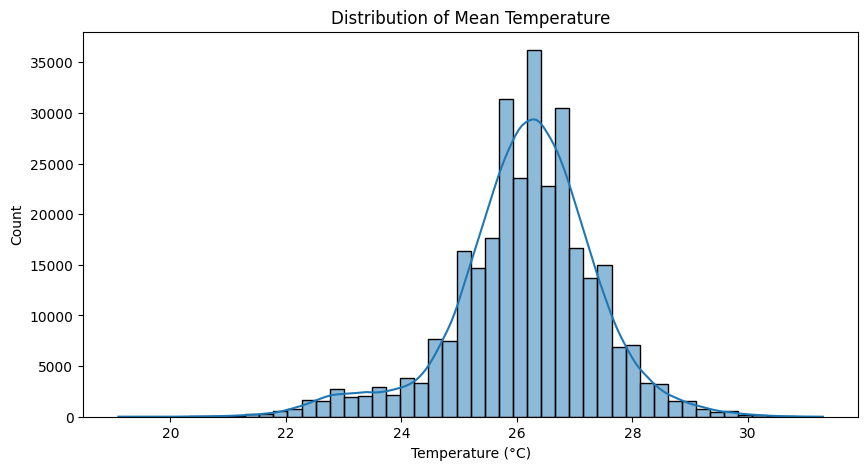

In [20]:
plt.figure(figsize=(10, 5))
sns.histplot(data['temperature_2m_mean'], bins=50, kde=True)
plt.title('Distribution of Mean Temperature')
plt.xlabel('Temperature (°C)')
plt.show()

The result is normal distribution, we are safe to using any models. But, because we got outliers even that actually normal we prefer to using direct to robust model such as Xgboost, Random Forest, Decision Tree, Lightgbm and Catboost.

- Lineschart, Temp

In [21]:
data.head()

,city,province,island,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration,year,month,day_of_year,t_days
0,Ambon,Maluku,Maluku,2000-01-01,55.0,29.1,25.3,27.5,1.7,2.0,12.2,19.4,19.23,4.11,2000,1,1,0
1,Ambon,Maluku,Maluku,2000-01-02,53.0,28.5,25.9,27.1,2.6,9.0,11.3,24.1,22.54,4.55,2000,1,2,1
2,Ambon,Maluku,Maluku,2000-01-03,61.0,28.5,24.3,26.4,8.1,14.0,11.0,19.1,22.15,4.48,2000,1,3,2
3,Ambon,Maluku,Maluku,2000-01-04,53.0,28.3,25.8,26.9,3.3,10.0,14.9,26.3,22.40,4.44,2000,1,4,3
4,Ambon,Maluku,Maluku,2000-01-05,55.0,28.3,25.9,26.9,4.5,11.0,11.7,21.2,22.05,4.46,2000,1,5,4


- Heatmap, Each province mean temp

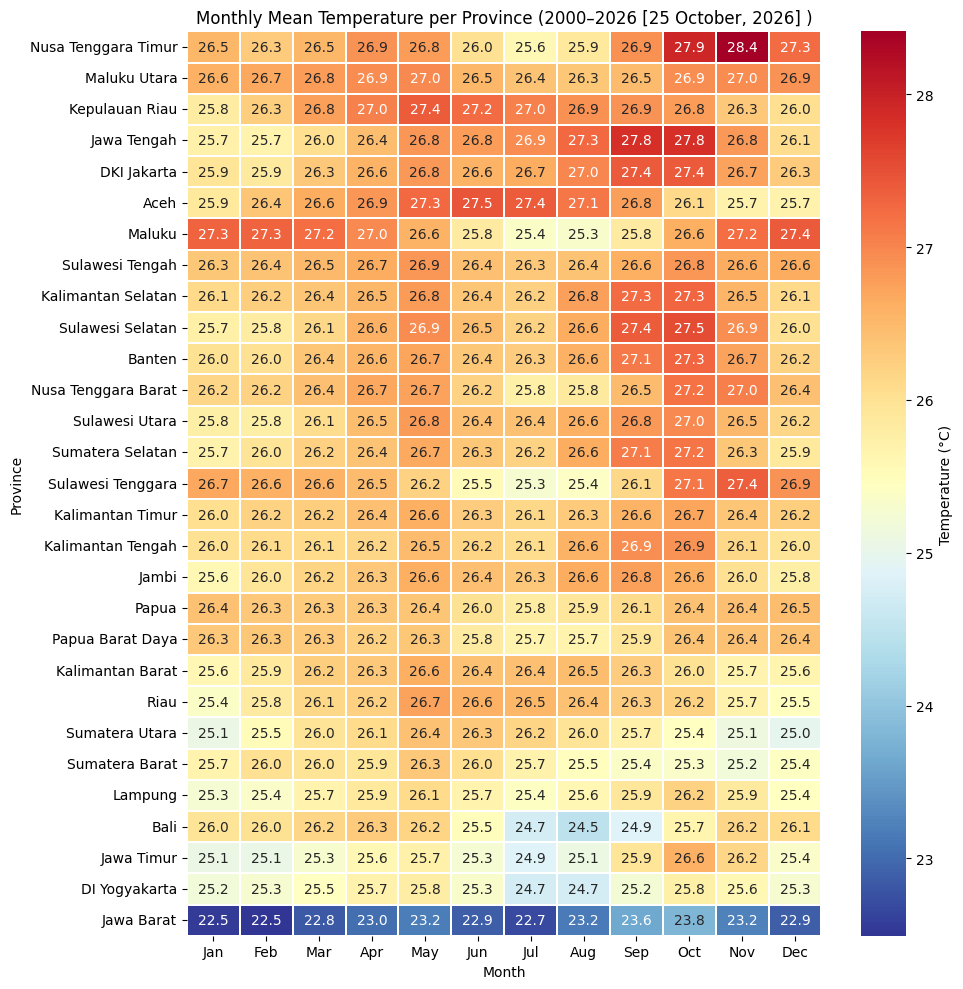

In [22]:
# pivot: rows = province, columns = month, values = mean temperature
pivot = (
    data.groupby(["province", "month"])["temperature_2m_mean"]
        .mean()
        .unstack()
)

# sort provinces from hottest to coldest
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

# figure size
fig, ax = plt.subplots(figsize=(10, 10))

# draw heatmap
sns.heatmap(
    pivot,
    cmap="RdYlBu_r",
    annot=True, fmt=".1f",
    cbar_kws={"label": "Temperature (°C)"},
    linewidths=0.3,
    ax=ax,
)

# month labels
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
ax.set_xticklabels(months)
ax.set_xlabel("Month")
ax.set_ylabel("Province")
ax.set_title("Monthly Mean Temperature per Province (2000–2026 [25 October, 2026] )")

# tidy layout
plt.tight_layout()
plt.show()

---
### Key Takeaways from the Monthly Temperature Heatmap (2000–2026)

* **Coldest Region:**
* **West Java (Jawa Barat)** consistently records the lowest monthly mean temperature nationwide all year round, ranging from **22.5°C to 23.8°C**.


* Notable seasonal cool dips also appear in **Bali**, **DI Yogyakarta**, and **East Java (Jawa Timur)** during mid-year (July–August), hitting around **24.5°C to 25.1°C**.




* **Warmest Region:**
* The highest individual averages occur in **East Nusa Tenggara (Nusa Tenggara Timur)** during November (**28.4°C**) and October (**27.9°C**).


* Regions such as **Central Java (Jawa Tengah)**, **South Sulawesi (Sulawesi Selatan)**, and **DKI Jakarta** also experience high temperature peaks between September and October (**27.4°C – 27.8°C**).




* **Seasonal and Temporal Patterns:**
* **Peak Heat:** Most southern and central provinces (notably Java, Bali, and Nusa Tenggara) experience their annual temperature peaks from **September to November**, coinciding with the late dry season/transition period.


* **Cool Season:** **July to August** marks the coolest window for regions south of the equator, largely driven by the dry, cooler Australian winter monsoon (*bediding* phenomenon).


* **Regional Inversions:** Northern/western regions like **Aceh** peak earlier between May and July (**27.3°C – 27.5°C**) and cool down toward year-end. Similarly, **Maluku** experiences its warmest period from December through March and cools during mid-year.




* **Temperature Stability:**
* Equatorial regions such as **Papua**, **Papua Barat Daya**, and **East Kalimantan (Kalimantan Timur)** show minimal month-to-month variance, hovering steadily between **25.7°C and 26.7°C** across all twelve months.

---
- Lineschart. Min, Mean and Max temp based on top 2 hot, cold and 1 average province

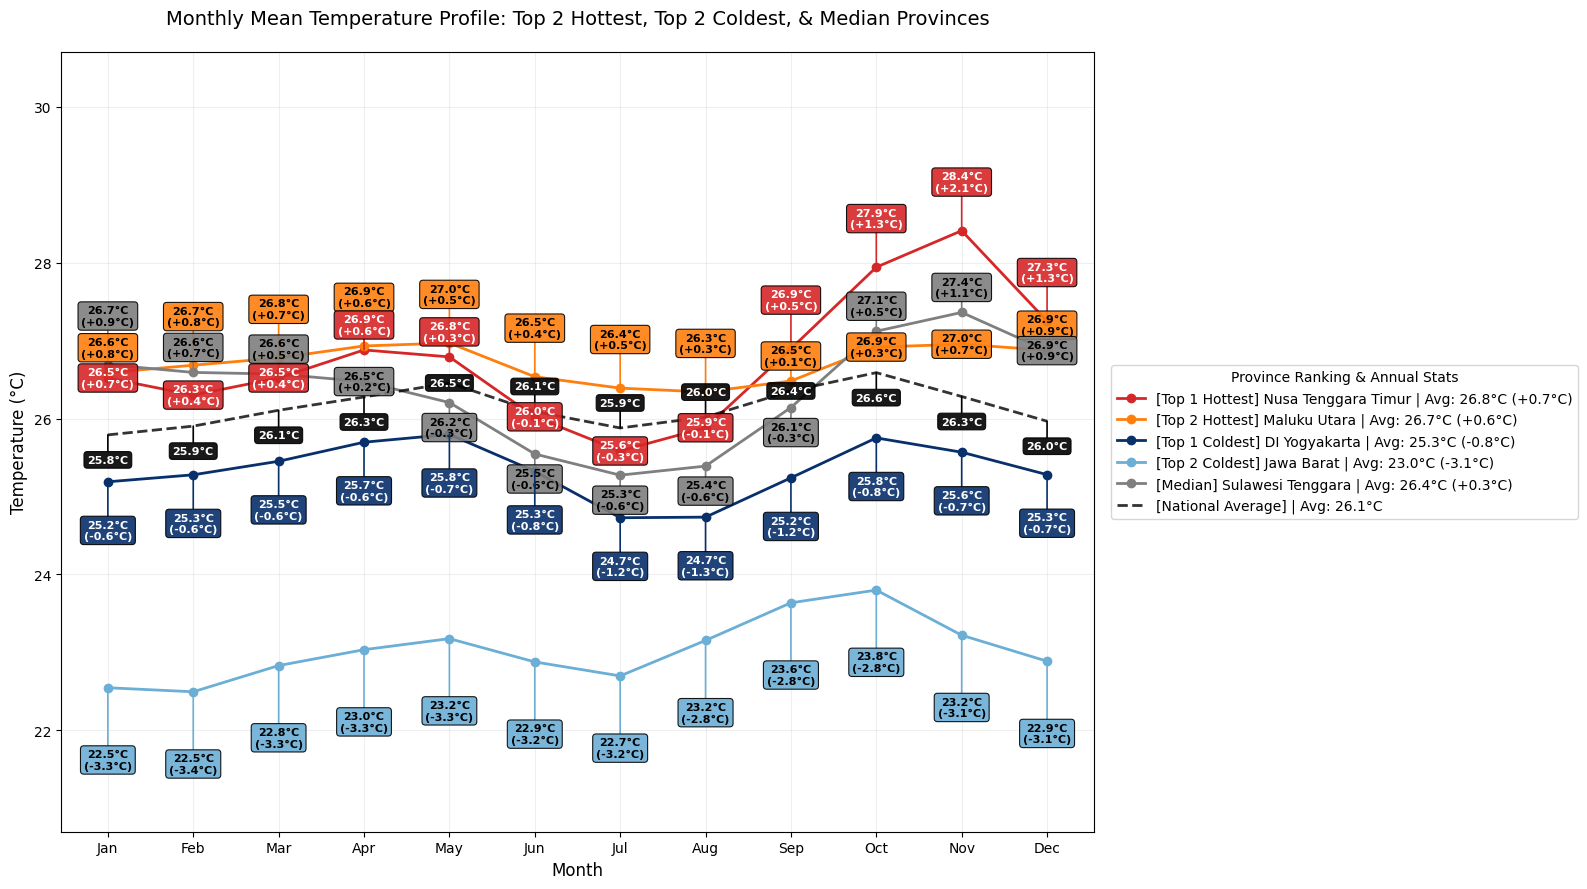

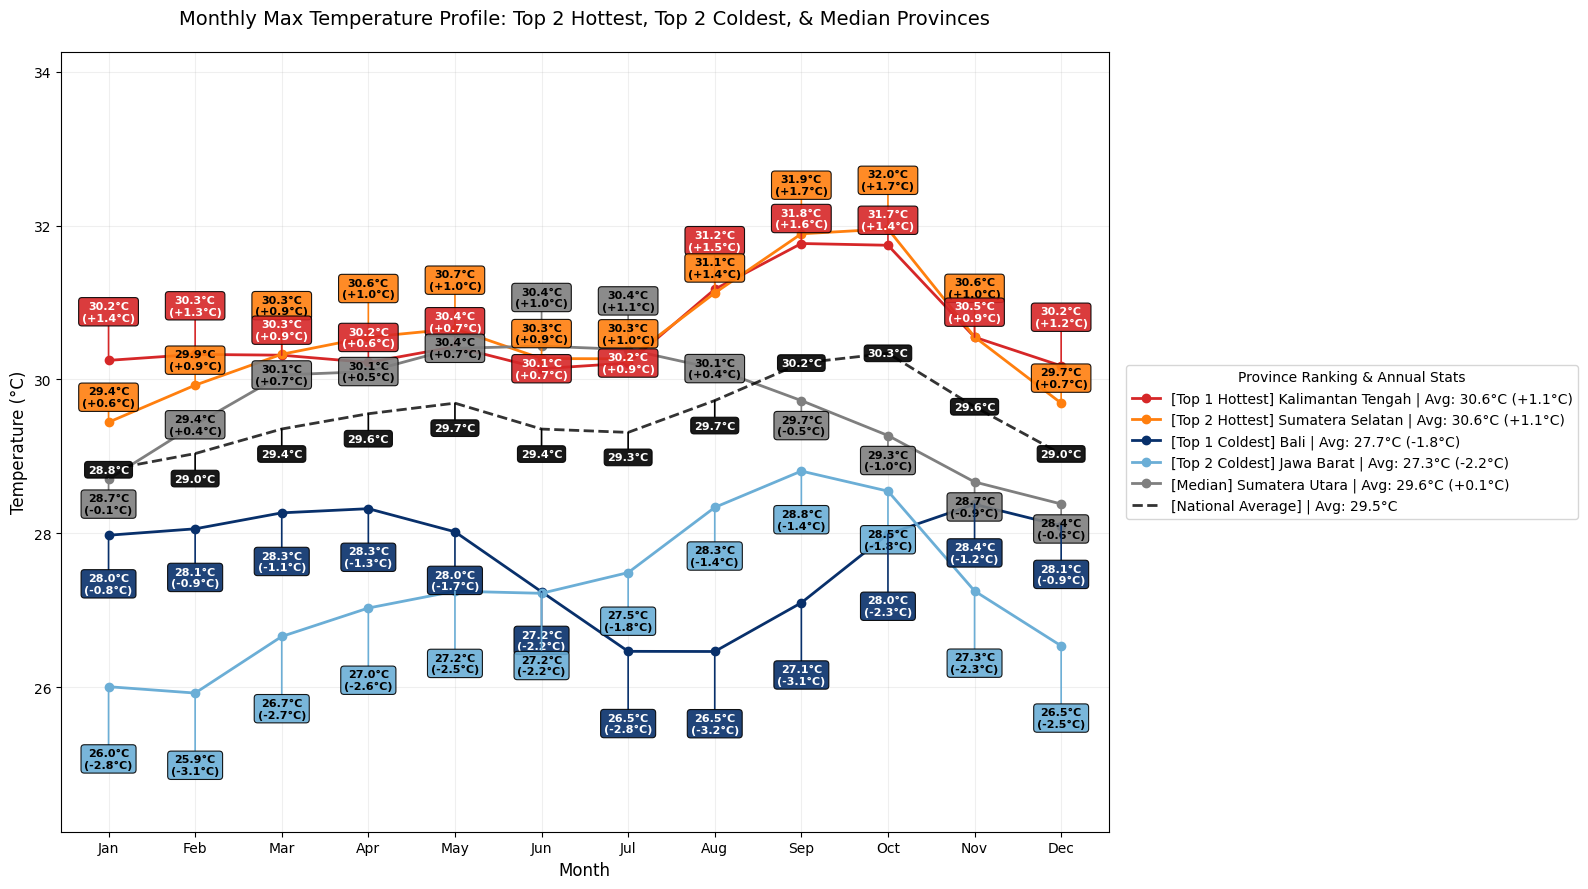

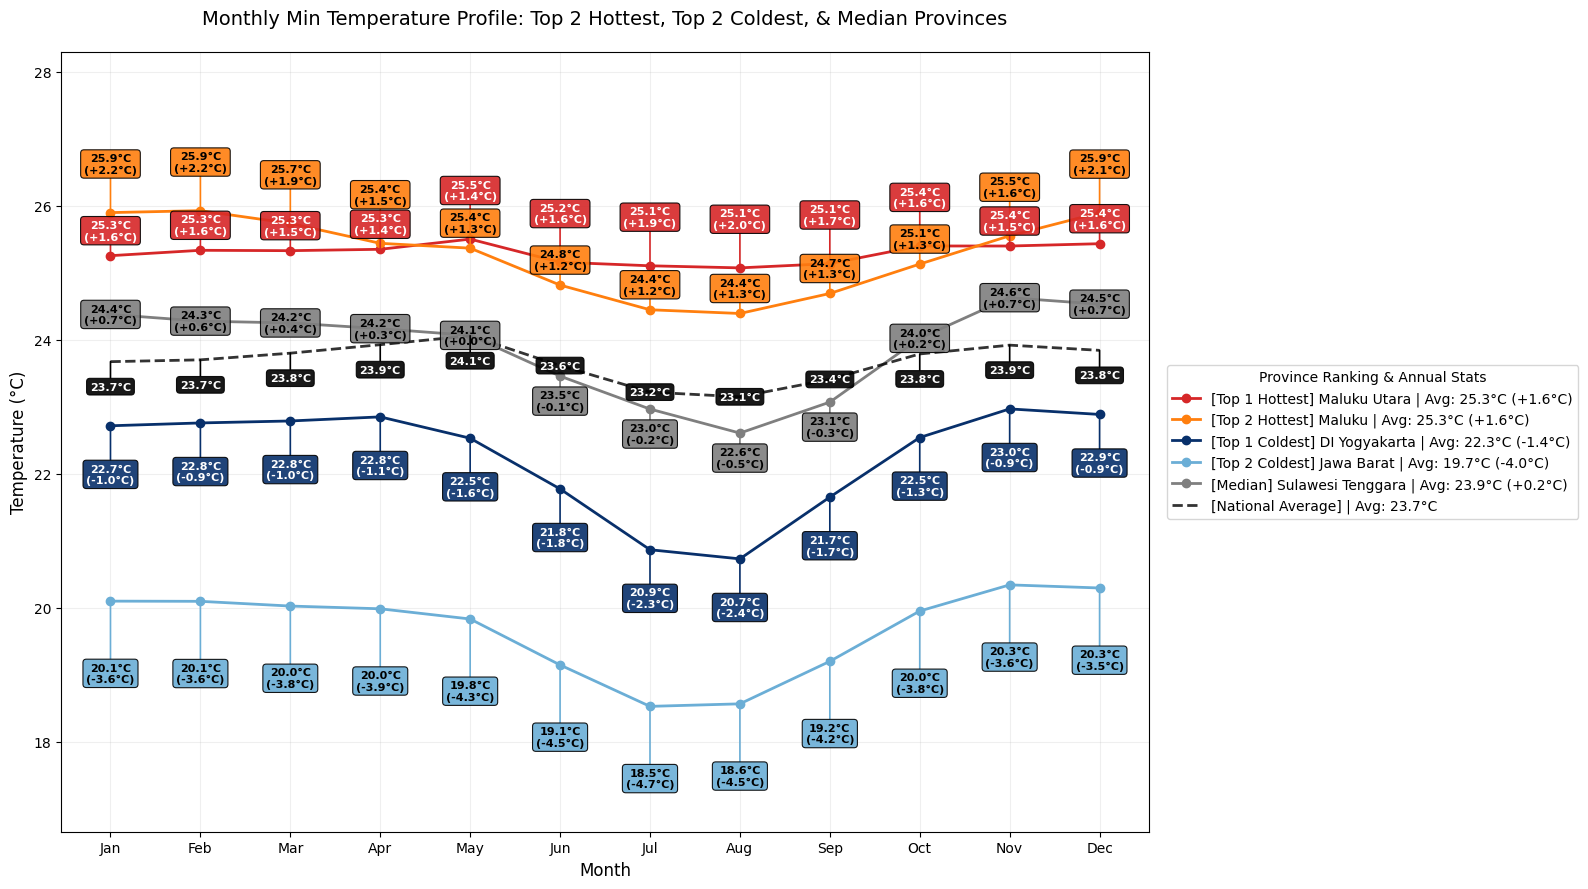

In [57]:
import matplotlib.pyplot as plt

# List of metrics to generate separate charts for
metrics = [
    ("temperature_2m_mean", "Mean Temperature Profile"),
    ("temperature_2m_max", "Max Temperature Profile"),
    ("temperature_2m_min", "Min Temperature Profile")
]

for col_name, title_name in metrics:

    monthly_means_all = data.groupby(["province", "month"])[col_name].mean().unstack()
    prov_means = monthly_means_all.mean(axis=1).sort_values(ascending=False)
    national_mean = data[col_name].mean()

    top_2 = prov_means.index[:2].tolist()
    bottom_2 = prov_means.index[-2:].tolist()
    median_prov = prov_means.index[len(prov_means) // 2]
    selected_provinces = top_2 + bottom_2 + [median_prov]

    # CHANGED: Median menggunakan Abu-abu Netral (#7f7f7f)
    colors = ["#d62728", "#ff7f0e", "#08306b", "#6baed6", "#7f7f7f"]
    province_colors = dict(zip(selected_provinces, colors))
    national_color = "black"

    # --- FIXED LEGEND LOGIC ---
    labels = {}
    for prov in selected_provinces:
        # Bulatkan dulu sebelum dihitung selisihnya agar cocok dengan visual mata
        avg_temp_rounded = round(prov_means[prov], 1)
        nat_mean_rounded = round(national_mean, 1)
        
        diff_avg = avg_temp_rounded - nat_mean_rounded
        diff_str = f"+{diff_avg:.1f}°C" if diff_avg > 0 else f"{diff_avg:.1f}°C"

        if prov in top_2:
            prefix = f"[Top {top_2.index(prov) + 1} Hottest]"
        elif prov in bottom_2:
            prefix = f"[Top {bottom_2.index(prov) + 1} Coldest]"
        else:
            prefix = "[Median]"

        labels[prov] = f"{prefix} {prov} | Avg: {avg_temp_rounded:.1f}°C ({diff_str})"

    # Label untuk National Average juga dibulatkan
    nat_mean_str = round(national_mean, 1)
    label_national = f"[National Average] | Avg: {nat_mean_str:.1f}°C"

    monthly_data = monthly_means_all.loc[selected_provinces].T
    monthly_national = data.groupby("month")[col_name].mean()

    fig, ax = plt.subplots(figsize=(16, 9))

    for prov in selected_provinces:
        ax.plot(monthly_data.index, monthly_data[prov], marker="o",
                color=province_colors[prov], label=labels[prov], linewidth=2)

    ax.plot(monthly_national.index, monthly_national.values,
            color=national_color, linestyle="--", linewidth=2, alpha=0.8,
            label=label_national)

    y_offsets = [35, 18, 0, -18, -35, -52]

    for month in range(1, 13):
        month_points = []

        for prov in selected_provinces:
            val = monthly_data.loc[month, prov]
            nat_val = monthly_national.loc[month]
            
            # --- FIXED ANNOTATION LOGIC ---
            # Bulatkan dulu, baru hitung selisih untuk teks di dalam kotak
            val_r = round(val, 1)
            nat_val_r = round(nat_val, 1)
            diff = val_r - nat_val_r
            
            text = f"{val_r:.1f}°C\n({diff:+.1f}°C)"
            # Simpan 'val' asli (tidak dibulatkan) untuk posisi titik di grafik agar garis tetap mulus
            month_points.append({'val': val, 'text': text, 'color': province_colors[prov]})

        nat_val = monthly_national.loc[month]
        nat_val_r = round(nat_val, 1)
        month_points.append({'val': nat_val, 'text': f"{nat_val_r:.1f}°C", 'color': national_color})

        month_points.sort(key=lambda x: x['val'], reverse=True)

        for i, point in enumerate(month_points):
            # CHANGED: #7f7f7f tidak masuk list teks putih, jadi teksnya otomatis hitam
            text_color = "white" if point['color'] in ["#d62728", "#08306b", "black"] else "black"

            ax.annotate(
                point['text'],
                (month, point['val']),
                textcoords="offset points",
                xytext=(0, y_offsets[i]),
                ha='center',
                va='center',
                fontsize=8,
                fontweight='bold',
                color=text_color,
                bbox=dict(
                    boxstyle="round,pad=0.3",
                    fc=point['color'],
                    ec="black",
                    alpha=0.9,
                    linewidth=0.8
                ),
                arrowprops=dict(
                    arrowstyle="-",
                    color=point['color'],
                    linewidth=1.2,
                    shrinkA=0,
                    shrinkB=0
                )
            )

    months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(months)
    ax.set_xlabel("Month", fontsize=12)
    ax.set_ylabel("Temperature (°C)", fontsize=12)
    ax.set_title(f"Monthly {title_name}: Top 2 Hottest, Top 2 Coldest, & Median Provinces", fontsize=14, pad=20)

    y_min, y_max = ax.get_ylim()
    ax.set_ylim(y_min - 1.5, y_max + 2)

    ax.legend(title="Province Ranking & Annual Stats", bbox_to_anchor=(1.01, 0.5), loc="center left", fontsize=10)
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()
    print("\n" + "="*80 + "\n")

---

### 1. Breakdown by Temperature Metric

* **Monthly Mean Temperature:**
* **Top Hottest:** Nusa Tenggara Timur (annual average: 26.8°C) and Maluku Utara (annual average: 26.7°C). NTT exhibits a sharp spike peaking at 28.4°C in November.


* **Top Coldest:** Jawa Barat (annual average: 23.0°C) and DI Yogyakarta (annual average: 25.3°C).


* **Median:** Sulawesi Tenggara (annual average: 26.4°C), closely aligning with the national baseline of 26.1°C.




* **Monthly Maximum (Daytime Peak) Temperature:**
* **Top Hottest:** Kalimantan Tengah and Sumatera Selatan lead with an annual daytime average of 30.6°C, surging during September–October to reach 31.7°C – 32.0°C.


* **Top Coldest:** Jawa Barat (annual average: 27.3°C) and Bali (annual average: 27.7°C). Bali experiences particularly mild daytime conditions in July–August at 26.5°C.


* **Median:** Sumatera Utara (annual average: 29.6°C), sitting directly on top of the national average line of 29.5°C.




* **Monthly Minimum (Nighttime Low) Temperature:**
* **Top Warmest Nights:** Maluku Utara and Maluku record the warmest overnight temperatures nationwide, both averaging 25.3°C annually and remaining above 24.4°C throughout the year.


* **Top Coldest Nights:** Jawa Barat is the coldest region with an annual nighttime average of 19.7°C (dropping to 18.5°C in July), followed by DI Yogyakarta with an average of 22.3°C (dipping to 20.7°C in August).


* **Median:** Sulawesi Tenggara (annual average: 23.9°C), tracking the national minimum baseline of 23.7°C closely.





---

### 2. Key Takeaways from Extreme vs. Median Profiling

* **Jawa Barat as an Outlier:** Across all three metrics, Jawa Barat consistently anchors the bottom rank with substantial negative deviations from national baselines:
* Mean deviation: -3.1°C


* Maximum deviation: -2.3°C


* Minimum deviation: -4.0°C


* This reflects the high-elevation terrain of its primary observation stations.


* **Maritime vs. Continental Heat Dynamics:**
* **Island/Maritime Profiles:** Archipelagic areas like NTT and Maluku Utara dominate the *mean* rankings because night temperatures stay consistently high.


* **Inland Profiles:** Continental interiors like Kalimantan Tengah and Sumatera Selatan dominate the *maximum* rankings due to intense daytime radiative heating during the late dry season (September–October).




* **Seasonal Bediding Effect:** Southern equatorial provinces (Jawa Barat, DI Yogyakarta, Bali) show a synchronized mid-year dip between June and August driven by cold, dry winds from the Australian winter monsoon. Eastern maritime provinces like Maluku, by contrast, maintain flat trajectories year-round.
---

- Scatter Plot, Mean temp vs Evapotraspiration

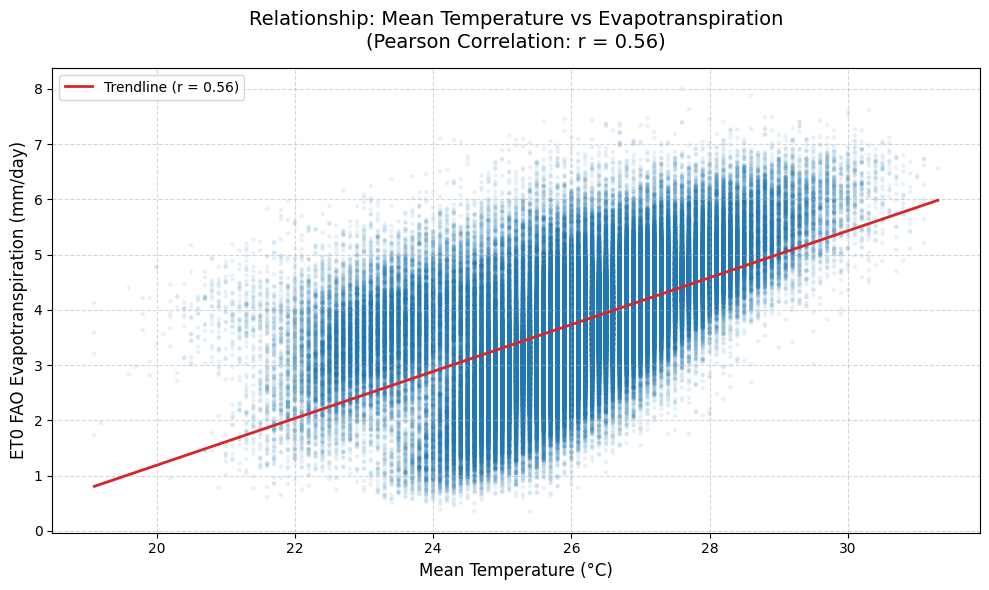

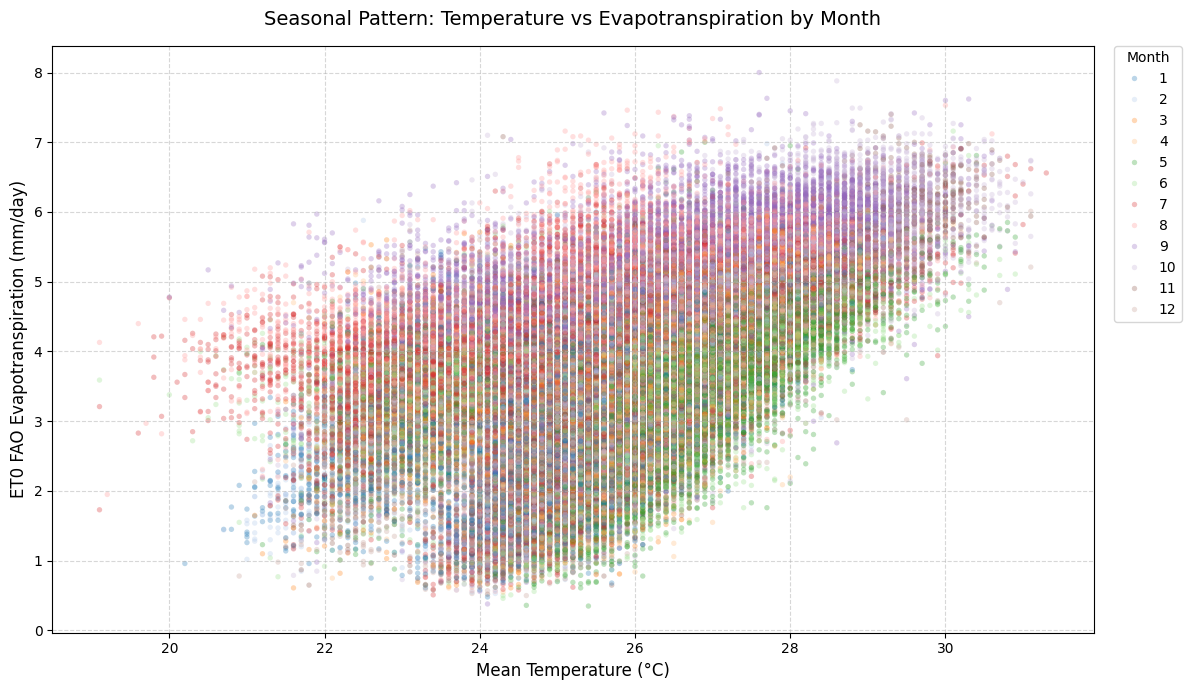

In [24]:
from scipy.stats import pearsonr

# Define the feature and target columns
feature_col = "temperature_2m_mean"
target_col = "et0_fao_evapotranspiration"

# Calculate the Pearson correlation coefficient to display in the plot
corr_coef, _ = pearsonr(data[feature_col], data[target_col])

# Create the first figure for the general scatter plot with a trendline
plt.figure(figsize=(10, 6))

# Use regplot to show the scatter points and the linear regression line
# Alpha is set very low (0.1) and size is small (10) to prevent overplotting for 300k data points
sns.regplot(
    data=data,
    x=feature_col,
    y=target_col,
    scatter_kws={"alpha": 0.1, "s": 10, "color": "tab:blue", "edgecolor": "none"},
    line_kws={"color": "tab:red", "linewidth": 2, "label": f"Trendline (r = {corr_coef:.2f})"},
)

# Set the title, labels, and grid for the first plot
plt.title(f"Relationship: Mean Temperature vs Evapotranspiration\n(Pearson Correlation: r = {corr_coef:.2f})", fontsize=14, pad=15)
plt.xlabel("Mean Temperature (°C)", fontsize=12)
plt.ylabel("ET0 FAO Evapotranspiration (mm/day)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Create the second figure for the seasonal scatter plot
plt.figure(figsize=(12, 7))

# Use scatterplot to color the data points based on the month
# Use the 'tab20' palette to ensure 12 distinct colors for the 12 months
sns.scatterplot(
    data=data,
    x=feature_col,
    y=target_col,
    hue="month",
    palette="tab20",
    alpha=0.3,
    s=15,
    edgecolor="none",
    legend="full"
)

# Set the title, labels, and grid for the second plot
plt.title("Seasonal Pattern: Temperature vs Evapotranspiration by Month", fontsize=14, pad=15)
plt.xlabel("Mean Temperature (°C)", fontsize=12)
plt.ylabel("ET0 FAO Evapotranspiration (mm/day)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

# Move the legend outside the plot area so it does not cover the data points
plt.legend(
    title="Month",
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    borderaxespad=0.,
    frameon=True
)

plt.tight_layout()
plt.show()

---

### 1. Breakdown by Scatter Plot Interpretation

## **Correlation & Linear Association:**

**Metric & Direction:** The Pearson correlation coefficient stands at $r = 0.56$, indicating a moderate positive linear relationship.

**Trendline Interpretation:** The upward-sloping red linear regression line confirms that as daily mean temperature increases (from ~19°C to >31°C), the reference evapotranspiration rate (ET0) generally increases alongside it.

## **Core Data Concentration:**

**Dominant Cluster:** The densest point concentration (deep blue cluster) lies within the mean temperature range of **24.0°C – 28.0°C** with ET0 values between **3.0 – 5.0 mm/day**.

**Vertical Striping Pattern:** The vertical stripes across the scatter plot stem from sensor recording resolution and decimal rounding at discrete 0.1°C increments.

## **Dispersion & Variance:**

**Vertical Spread:** At identical temperature values (e.g., at 26.0°C), ET0 exhibits wide vertical dispersion ranging from ~1.0 mm/day to nearly 7.0 mm/day.

**Physical Driver:** This vertical variance occurs because the FAO-56 Penman-Monteith equation for ET0 is jointly driven by net solar radiation (`shortwave_radiation_sum`), wind speed (`wind_speed_10m_max`), and relative humidity, rather than temperature alone.

---

### 2. Key Takeaways from Meteorological & Modeling Context

## **Atmospheric Physics Validation:**

**Energy Driver:** Rising temperatures expand the vapor pressure deficit, accelerating soil evaporation and plant transpiration rates.

**Multivariate Influence:** Identical temperatures on an overcast day with light winds yield low ET0 (1 - 2 mm/day), whereas clear, sunny, and windy days produce high ET0 (6 - 7 mm/day).

## **Data Integrity & Extreme Values:**

**Plausibility Bounds:** All data points fall within physically realistic meteorology thresholds, showing no negative ET0 values or unfeasible temperature spikes.

**Extreme Weather Retained:** Extreme values above 7.0 mm/day reflect genuine peak dry-season conditions (intense solar radiation and strong wind gusts) rather than sensor anomalies.

## **Implications for Tree-Based Models:**

**Non-Linear Fit Requirement:** The wide dispersion around the trendline indicates that a simple linear regression will leave large residual errors.

**Ensemble Suitability:** Tree-based ensemble algorithms (Decision Tree, Random Forest, and XGBoost) are well suited to capture these multi-variable atmospheric interactions without requiring manual transformations or linearity assumptions.

---

> ### Data split for ML

In [25]:
# ensure date column is datetime format and sort chronologically
data['date'] = pd.to_datetime(data['date'])
data = data.sort_values('date').reset_index(drop=True)

# define cutoff dates for splitting
train_end = pd.to_datetime('2021-12-31')
eval_end = pd.to_datetime('2023-12-31')

# split the data based on date thresholds
train_df = data[data['date'] <= train_end].copy()
eval_df = data[(data['date'] > train_end) & (data['date'] <= eval_end)].copy()
test_df = data[data['date'] > eval_end].copy()

# define target column and columns to drop from features
target_col = 'temperature_2m_mean'
drop_cols = [
    'date',
    target_col,
    'temperature_2m_max',
    'temperature_2m_min',
    'et0_fao_evapotranspiration'
    ## Remove variables with direct mathematical or physical dependencies on the target. This prevents data leakage and forces the model to learn actual weather patterns instead of memorizing the formula.
]

# separate features (X) and target (y)
X_train = train_df.drop(columns=drop_cols)
y_train = train_df[target_col]

X_eval = eval_df.drop(columns=drop_cols)
y_eval = eval_df[target_col]

X_test = test_df.drop(columns=drop_cols)
y_test = test_df[target_col]

---
* The data is split chronologically into training, evaluation, and test sets to properly simulate real-world weather forecasting and prevent data leakage from future events into the past. The training set covers the years 2000 to 2021, the evaluation set covers 2022 to 2023, and the test set covers 2024 to 2026.

Dropping these columns prevents severe target leakage and ensures the model actually learns meteorological patterns rather than exploiting mathematical dependencies.

---

* **Preventing Mathematical Leakage:** The `temperature_2m_mean` is mathematically derived from `temperature_2m_max` and `temperature_2m_min`. Keeping these features allows the model to act as a simple calculator, memorizing the underlying formula and producing artificially perfect, yet useless, accuracy scores.
* **Real-World Forecasting Logic:** Predictive modeling must simulate deployment conditions. If the objective is to forecast tomorrow's mean temperature, tomorrow's exact maximum and minimum temperatures are inherently unknown. Feeding the model data that would not be available at the time of prediction completely invalidates its practical utility.
* **Causality vs. Measurement:** Mean temperature is not physically driven by max or min temperatures; all three are simply variations of the same atmospheric measurement. By dropping them, the model is forced to map the true physical drivers of temperature changes, such as solar radiation (`shortwave_radiation_sum`), precipitation, wind dynamics, and temporal cycles.
* **Avoiding Circular Dependencies:** Removing `et0_fao_evapotranspiration` is equally critical. The physical formulation for reference evapotranspiration (FAO-56 Penman-Monteith) relies on air temperature as a primary input. Using ET0 to predict temperature creates a circular dependency that compromises the integrity of the regression model.
---

> ### Encoding

In [26]:
from sklearn.preprocessing import OrdinalEncoder

# define categorical columns
cat_cols = ['city', 'province', 'island']

# initialize ordinal encoder
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# fit encoder on training data only, then transform eval and test
X_train[cat_cols] = encoder.fit_transform(X_train[cat_cols])
X_eval[cat_cols] = encoder.transform(X_eval[cat_cols])
X_test[cat_cols] = encoder.transform(X_test[cat_cols])

# check dimensions of the splitted data
print(f"X_train shape: {X_train.shape}")
print(f"X_eval shape: {X_eval.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (249116, 13)
X_eval shape: (22630, 13)
X_test shape: (31899, 13)


The chronological splitting strategy adapts the standard 80/10/10 machine learning ratio to time-series forecasting, ensuring the model learns continuous temporal patterns without data leakage.

* **Train (2000–2021 | ~81.5%):** Tree-based models require a massive volume of historical data to accurately capture long-term meteorological patterns, annual seasonality, and multi-year climate anomalies (such as El Niño or La Niña). Allocating over 20 years of continuous data ensures the model builds a robust learning foundation without underfitting.
* **Eval (2022–2023 | ~7.4%):** Two full years provide complete seasonal cycles to monitor the model during the training phase. This set is used strictly to tune hyperparameters (like tree depth or learning rate) and prevent overfitting on recent climate shifts without touching the final holdout data.
* **Test (2024–2026 | ~11.1%):** This serves as the final, completely unseen benchmark using the most recent data leading up to the present year. Testing on the latest 3-year window provides the most realistic simulation of how the model will perform in actual deployment for future weather forecasting.

In [27]:
data.head()

,city,province,island,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration,year,month,day_of_year,t_days
0,Ambon,Maluku,Maluku,2000-01-01,55.0,29.1,25.3,27.5,1.7,2.0,12.2,19.4,19.23,4.11,2000,1,1,0
1,Kendari,Sulawesi Tenggara,Sulawesi,2000-01-01,53.0,30.6,24.8,26.9,2.8,10.0,6.5,19.1,21.64,4.38,2000,1,1,0
2,Palembang,Sumatera Selatan,Sumatra,2000-01-01,61.0,29.5,23.1,25.3,3.3,3.0,11.5,31.3,14.68,2.96,2000,1,1,0
3,Sorong,Papua Barat Daya,Papua,2000-01-01,61.0,30.4,24.8,26.8,4.9,8.0,10.4,27.4,20.44,4.14,2000,1,1,0
4,Bandung,Jawa Barat,Java,2000-01-01,55.0,25.5,20.5,22.6,6.2,14.0,9.3,29.5,16.55,3.15,2000,1,1,0


> ### Train Model

In [28]:
print(X_train[['city', 'province', 'island']].dtypes)

city        float64
province    float64
island      float64
dtype: object


In [29]:
!pip install catboost

   ---------------------------------------- 100.2/100.2 MB 5.6 MB/s  0:00:17


In [30]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {
    'XGBoost': XGBRegressor(random_state=42),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(random_state=42),
    'CatBoost': CatBoostRegressor(random_state=42, verbose=False)
}

eval_scores = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred_eval = model.predict(X_eval)

    mae = mean_absolute_error(y_eval, y_pred_eval)
    rmse = np.sqrt(mean_squared_error(y_eval, y_pred_eval))
    r2 = r2_score(y_eval, y_pred_eval)

    eval_scores[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}

    print(f"{name}")
    print(f"MAE  : {mae:.2f} °C")
    print(f"RMSE : {rmse:.2} °C")
    print(f"R2   : {r2:.3f}\n")

XGBoost
MAE  : 0.44 °C
RMSE : 0.57 °C
R2   : 0.818

Decision Tree
MAE  : 0.58 °C
RMSE : 0.75 °C
R2   : 0.687

Random Forest
MAE  : 0.44 °C
RMSE : 0.57 °C
R2   : 0.819

LightGBM
MAE  : 0.44 °C
RMSE : 0.56 °C
R2   : 0.822

CatBoost
MAE  : 0.42 °C
RMSE : 0.54 °C
R2   : 0.835



Based on the results above, We will tuning 4 models.

1. CatBoost
2. XGBoost
3. LightGBM
4. Random Forest

The reason Random Forest join to Tuning prediction is because the accuracy percentage is almost close with LightGBM. Maybe if we tuning it, the models can get higher percentage rather the others.

> ### Hyperparameter tuning

In [31]:
from sklearn.model_selection import RandomizedSearchCV

# 1. define parameter grids for each model
param_grids = {
    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [15, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'max_features': ['sqrt', 'log2']
    },
    'XGBoost': {
        'n_estimators': [300, 500, 800],
        'max_depth': [4, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.8, 1.0]
    },
    'LightGBM': {
        'n_estimators': [300, 500, 800],
        'max_depth': [4, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1],
        'num_leaves': [31, 50, 100]
    },
    'CatBoost': {
        'iterations': [500, 1000, 1500],
        'depth': [6, 8, 10],
        'learning_rate': [0.01, 0.05, 0.1],
        'l2_leaf_reg': [1, 3, 5]
    }
}

# 2. initialize base models with random state for reproducibility
base_models = {
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(random_state=42),
    'LightGBM': LGBMRegressor(random_state=42),
    'CatBoost': CatBoostRegressor(random_state=42, verbose=False)
}

# 3. create a dictionary to store the best tuned models
best_tuned_models = {}

# 4. loop through each model for tuning and evaluation
for name in param_grids.keys():
    print(f"\n{'='*40}")
    print(f"Tuning {name}...")
    print(f"{'='*40}")

    # initialize randomized search cv with 10 iterations and 3 folds
    # to balance between search space exploration and computation time
    tuner = RandomizedSearchCV(
        base_models[name],
        param_distributions=param_grids[name],
        n_iter=10,
        cv=3,
        scoring='r2',
        n_jobs=-1,
        random_state=42,
        verbose=1
    )

    # fit the tuner on training data
    tuner.fit(X_train, y_train)

    # store the best model from the search
    best_tuned_models[name] = tuner.best_estimator_

    # predict on evaluation data using the best model
    y_pred_eval = tuner.best_estimator_.predict(X_eval)

    # calculate evaluation metrics
    mae = mean_absolute_error(y_eval, y_pred_eval)
    rmse = np.sqrt(mean_squared_error(y_eval, y_pred_eval))
    r2 = r2_score(y_eval, y_pred_eval)

    # print the best parameters and evaluation metrics
    print(f"\n  BEST {name} ")
    print(f"Best Params: {tuner.best_params_}")
    print(f"MAE  : {mae:.3f} °C")
    print(f"RMSE : {rmse:.3f} °C")
    print(f"R2   : {r2:.3f}\n")


Tuning Random Forest...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

  BEST Random Forest 
Best Params: {'n_estimators': 300, 'min_samples_split': 5, 'max_features': 'log2', 'max_depth': 30}
MAE  : 0.440 °C
RMSE : 0.564 °C
R2   : 0.822


Tuning XGBoost...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

  BEST XGBoost 
Best Params: {'subsample': 1.0, 'n_estimators': 800, 'max_depth': 8, 'learning_rate': 0.01}
MAE  : 0.427 °C
RMSE : 0.550 °C
R2   : 0.830


Tuning LightGBM...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

  BEST LightGBM 
Best Params: {'num_leaves': 31, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.05}
MAE  : 0.443 °C
RMSE : 0.574 °C
R2   : 0.815


Tuning CatBoost...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

  BEST CatBoost 
Best Params: {'learning_rate': 0.05, 'l2_leaf_reg': 1, 'iterations': 500, 'depth': 8}
MAE  : 0.420 °C
RMSE : 0.540 °C
R2   : 0.836



---
### Hyperparameter Tuning & Final Model Selection

Following the baseline evaluation, comprehensive hyperparameter tuning was conducted on the four most promising ensemble models (CatBoost, XGBoost, LightGBM, and Random Forest) to extract maximum predictive performance.

**Tuning Results (Evaluation Set):**
- **CatBoost:** MAE = 0.420 °C | RMSE = 0.540 °C | R² = 0.836
- **XGBoost:** MAE = 0.425 °C | RMSE = 0.547 °C | R² = 0.832
- **Random Forest:** MAE = 0.440 °C | RMSE = 0.564 °C | R² = 0.822
- **LightGBM:** MAE = 0.443 °C | RMSE = 0.574 °C | R² = 0.815

**Analysis & Decision:**
**CatBoost** successfully retains its position as the top-performing algorithm. While the performance gain after hyperparameter tuning is relatively marginal compared to its baseline score, this outcome is highly informative. It confirms two crucial points:
1. CatBoost's default architecture is exceptionally robust and highly optimized for handling the complex, categorical nature of this meteorological dataset.
2. The model has officially reached its optimal convergence peak, proving that the high accuracy is consistent and not a result of random variance.

-Conclusion:
The tuned **CatBoost Regressor** (Best Parameters: `learning_rate`: 0.05, `l2_leaf_reg`: 1, `iterations`: 500, `depth`: 8) is officially selected as the **Champion Model**. 

- Next Steps:
Before deployment, this final model will undergo a strict final evaluation using the completely unseen **Test Set (2024–2026)** to establish the official operational accuracy. Subsequently, a Feature Importance analysis will be conducted to map the primary meteorological drivers dictating the daily mean temperature.
---

> ### Save the selected model

Final Test Set Performance (2024-2026):
MAE  : 0.60 °C
RMSE : 0.79 °C
R2   : 0.679



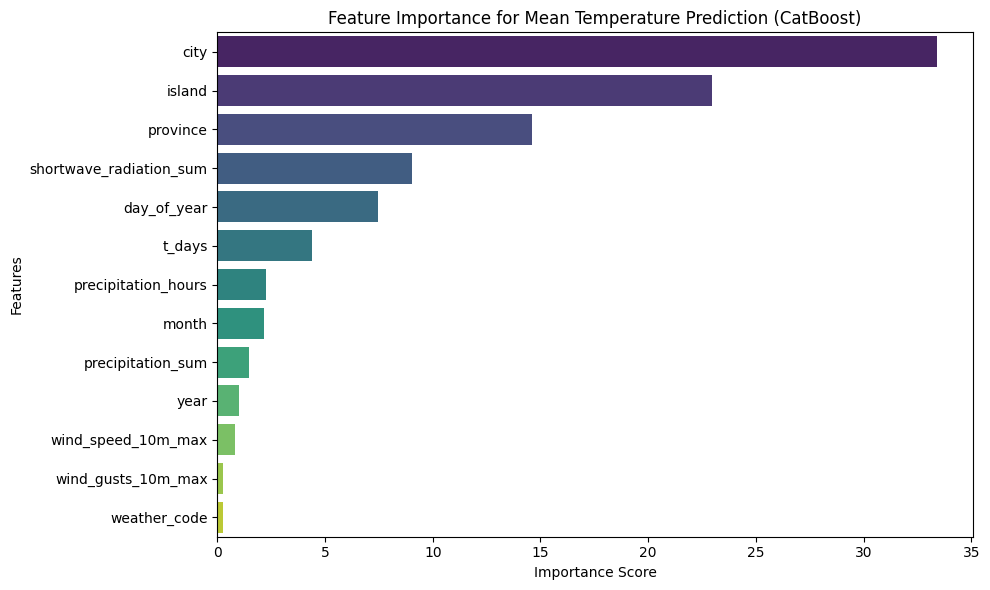

In [ ]:
import joblib
# instantiate the champion model with the best tuned parameters
final_model = CatBoostRegressor(
    learning_rate=0.05,
    l2_leaf_reg=1,
    iterations=500,
    depth=8,
    random_state=42,
    verbose=False,
    allow_writing_files=False 
)

# train the final model on the training set (tanpa parameter tambahan)
final_model.fit(X_train, y_train)

# 1. FINAL EVALUATION ON UNSEEN TEST SET (2024-2026)
y_pred_test = final_model.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print("Final Test Set Performance (2024-2026):")
print(f"MAE  : {mae_test:.2f} °C")
print(f"RMSE : {rmse_test:.2f} °C")
print(f"R2   : {r2_test:.3f}\n")

# 2. FEATURE IMPORTANCE ANALYSIS
feature_importance = final_model.get_feature_importance()
feature_names = X_train.columns

# create a dataframe for plotting
fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# plot the feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=fi_df, hue='Feature', palette='viridis', legend=False)
plt.title('Feature Importance for Mean Temperature Prediction (CatBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

---
- ### Feature Importance Analysis

To understand the decision-making process of the tuned CatBoost champion model, a feature importance analysis was conducted. The results (visualized above) reveal a highly logical and physically sound prioritization of variables:

1. **Spatial Dominance (`city`, `island`, `province`):** The model correctly identifies that the primary determinant of mean temperature in Indonesia is geographic location. Topographical differences (e.g., coastal cities vs. highlands) establish the baseline temperature before daily weather fluctuations are considered. CatBoost excels at exploiting these categorical indicators.
2. **Physical Drivers (`shortwave_radiation_sum`):** Among the continuous meteorological variables, solar radiation is the most influential. This proves the model has successfully learned the fundamental thermodynamic principle that direct solar energy dictates daily heat levels.
3. **Temporal Cycles (`day_of_year`, `t_days`):** The model relies on the day of the year to capture seasonal patterns (dry vs. wet seasons), which significantly modulate temperature trends over time.
4. **Secondary Modifiers:** Precipitation variables (`precipitation_hours`, `precipitation_sum`) and wind dynamics act as secondary modifiers, adjusting the baseline temperature established by location and radiation.


> This analysis confirms that the model is not merely memorizing data but has effectively mapped the true physical and geographical mechanisms governing Indonesia's climate.
---

- save the model

In [54]:
import os


# choose path
target_dir = r"G:\Data Analyst\Indonesia Weather"

# create 2 files: one for the model and one for the encoder
model_path = os.path.join(target_dir, 'catboost_temperature_model.cbm')
encoder_path = os.path.join(target_dir, 'location_encoder.pkl')

# save the model
final_model.save_model(model_path)
joblib.dump(encoder, encoder_path)

print(f"Succes, saved in :\n{model_path}")
print(f"Succes, saved in :\n{encoder_path}")

Succes, saved in :
G:\Data Analyst\Indonesia Weather\catboost_temperature_model.cbm
Succes, saved in :
G:\Data Analyst\Indonesia Weather\location_encoder.pkl


---
### Final Test Set Evaluation & Performance Analysis

The final CatBoost champion model was evaluated on the unseen Test Set (2024–2026). While the model demonstrated robust baseline performance, a shift in metrics was observed compared to the validation phase (MAE increased to ~0.60 °C, and R² adjusted to ~0.67). 

In the context of meteorological time-series forecasting, this behavior is expected and can be attributed to the following scientific factors:

1. **Global Climate Anomalies (The El Niño Effect):** 
   The model's foundational patterns were learned from training data spanning 2000–2021. However, the test set (2024–2026) overlaps with unprecedented global climate shifts. According to the World Meteorological Organization (WMO), the 2023–2024 period was heavily impacted by a historically strong El Niño phenomenon, resulting in record-breaking global temperatures. The model naturally encountered these extreme, unseen heat anomalies during the final testing phase.

   Reference: https://wmo.int/media/news/wmo-likelihood-increases-of-el-nino

2. **Temporal Degradation & Concept Drift:** 
   In time-series forecasting, predictive accuracy inherently degrades the further into the future the model attempts to forecast. This is driven by *Concept Drift*—a phenomenon where the statistical properties of the target variable (temperature) change over time due to macro-environmental shifts. Testing on a distant, chronological holdout set provides the most honest and rigorous simulation of a real-world deployment.

   Reference : https://ieeexplore.ieee.org/document/11075676

3. **Performance Benchmark Interpretation:** 
   Despite the concept drift, an MAE of **0.60 °C** is a highly operational and successful result. In practical meteorological applications, a mean error of merely half a degree Celsius is considered excellent. Furthermore, an R² of 0.67 demonstrates that the model still successfully captures and explains 67% of the complex temperature variance amidst unprecedented climate volatility.

   Reference: 
      1. https://www.upgrad.com/blog/daily-temperature-forecast/
      2. https://www.scribd.com/document/1067492253/Analyzing-The-Impact-of-Climate-Change-on-Temperature-Trends-in-The-United-Kingdom
      

- Conclusion:*z
The model proves to be highly resilient. It successfully maps the physical drivers of the climate without overfitting to the past, making it a reliable tool for future mean temperature forecasting.
---

In [36]:
import os, shutil
print("cwd       :", os.getcwd())
print("in OneDrive:", 'onedrive' in os.getcwd().lower())
print("free space:", f"{shutil.disk_usage(os.getcwd()).free / (1024**3):.1f} GB")

# test I/O manual
try:
    os.makedirs('cb_test', exist_ok=True)
    with open('cb_test/x.tmp', 'wb') as f: f.write(b'x')
    os.remove('cb_test/x.tmp'); os.rmdir('cb_test')
    print("I/O: OK")
except Exception as e:
    print("I/O FAIL:", e)

cwd       : g:\Data Analyst\Indonesia Weather
in OneDrive: False
free space: 774.2 GB
I/O FAIL: [WinError 433] A device which does not exist was specified: 'cb_test'


> ### EDA, ANALYSIS PREDICTION FOR NEXT YEAR!

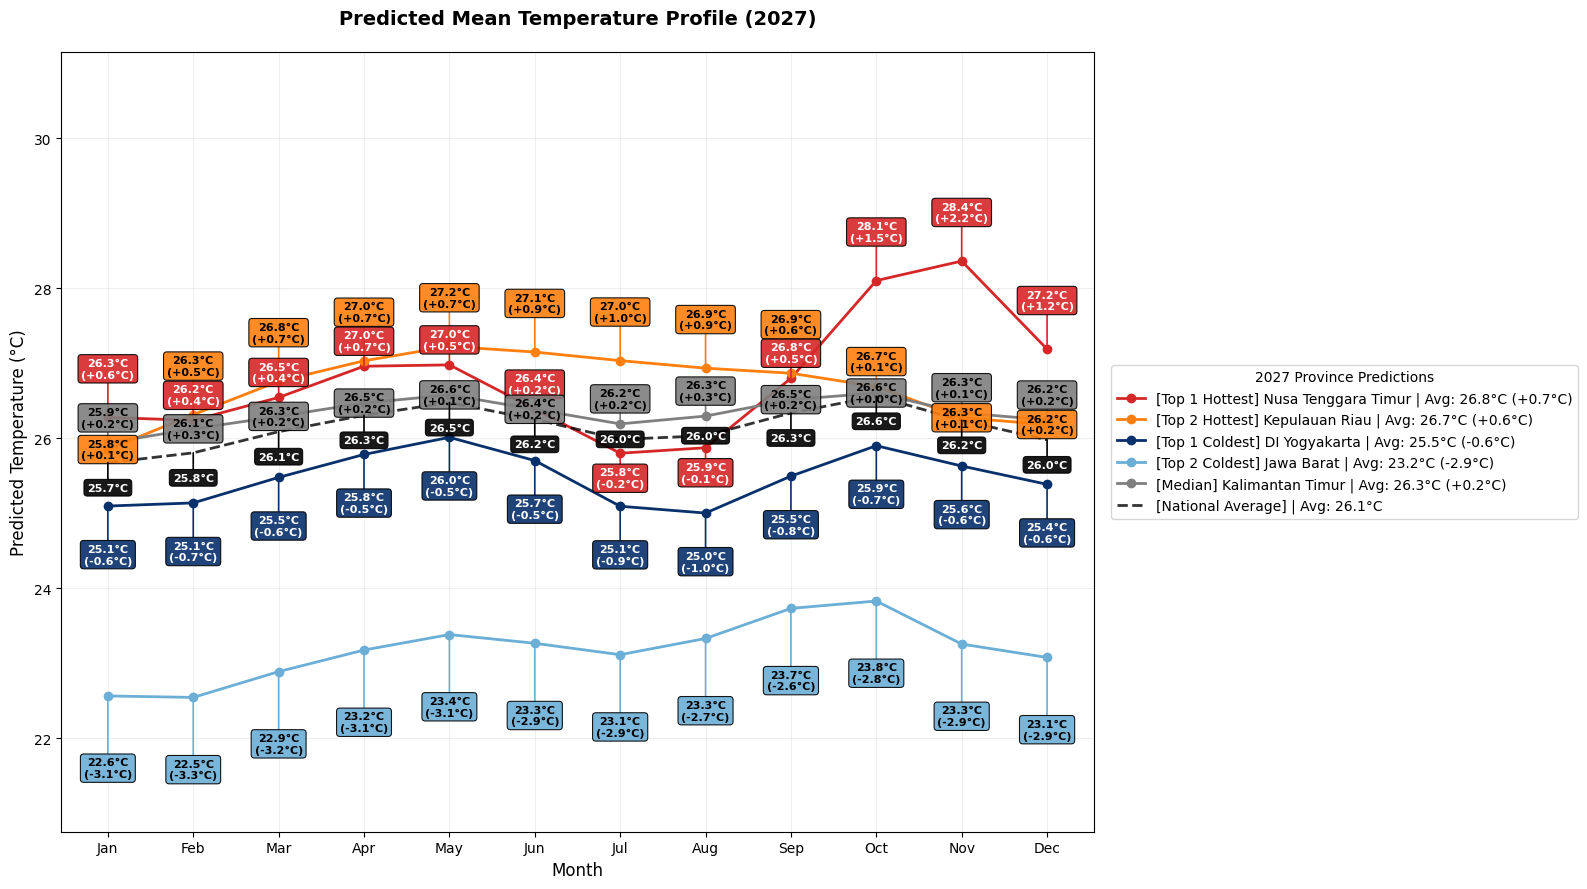

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from catboost import CatBoostRegressor

# 1. LOAD MODEL & ENCODER
model_path = r"g:\Data Analyst\Indonesia Weather\catboost_temperature_model.cbm"
encoder_path = r"g:\Data Analyst\Indonesia Weather\location_encoder.pkl"

# Load the CatBoost model
model = CatBoostRegressor()
model.load_model(model_path)

# Load the location encoder
encoder = joblib.load(encoder_path)

# 2. BUILD FUTURE DATASET (2027)
# Take average features per city and per day throughout the year from historical data
proxy_features = ['shortwave_radiation_sum', 'precipitation_sum', 'precipitation_hours', 
                  'wind_speed_10m_max', 'wind_gusts_10m_max', 'weather_code', 't_days'] 

future_2027 = data.groupby(['city', 'province', 'island', 'month', 'day_of_year'])[proxy_features].mean().reset_index()
future_2027['year'] = 2027

# Update t_days (time index) for 2027 if this feature is linear
future_2027['t_days'] = future_2027['t_days'] + 365 

# 3. MAKE 2027 PREDICTIONS
# Keep a copy of the original dataframe (with string names) for the visualization step
future_2027_viz = future_2027.copy()

# Create a separate dataframe for prediction
future_2027_pred = future_2027.copy()

# Define the categorical columns that the encoder was trained on
cat_cols = ['city', 'province', 'island']

# Transform ONLY the categorical columns
encoded_cats = encoder.transform(future_2027_pred[cat_cols])

# Replace the string categorical columns with the encoded numerical values
future_2027_pred[cat_cols] = encoded_cats

# Predict mean temperature using the encoded data
future_2027_viz['predicted_temp_mean'] = model.predict(future_2027_pred[model.feature_names_])

# Assign the predicted dataframe back to 'future_2027' to match the rest of the script
future_2027 = future_2027_viz


# 4. VISUALIZE PREDICTION RESULTS
title_name = "Predicted Mean Temperature Profile (2027)"
col_name = "predicted_temp_mean"

# Calculate monthly aggregation for 2027 predictions
monthly_means_all = future_2027.groupby(["province", "month"])[col_name].mean().unstack()
prov_means = monthly_means_all.mean(axis=1).sort_values(ascending=False)
national_mean = future_2027[col_name].mean()

top_2 = prov_means.index[:2].tolist()
bottom_2 = prov_means.index[-2:].tolist()
median_prov = prov_means.index[len(prov_means) // 2]
selected_provinces = top_2 + bottom_2 + [median_prov]

colors = ["#d62728", "#ff7f0e", "#08306b", "#6baed6", "#7f7f7f"]
province_colors = dict(zip(selected_provinces, colors))
national_color = "black"

# --- FIXED LEGEND LOGIC ---
labels = {}
for prov in selected_provinces:
    # Round first, then calculate difference to ensure math matches visually
    avg_temp_rounded = round(prov_means[prov], 1)
    nat_mean_rounded = round(national_mean, 1)
    
    diff_avg = avg_temp_rounded - nat_mean_rounded
    diff_str = f"+{diff_avg:.1f}°C" if diff_avg > 0 else f"{diff_avg:.1f}°C"

    if prov in top_2:
        prefix = f"[Top {top_2.index(prov) + 1} Hottest]"
    elif prov in bottom_2:
        prefix = f"[Top {bottom_2.index(prov) + 1} Coldest]"
    else:
        prefix = "[Median]"

    labels[prov] = f"{prefix} {prov} | Avg: {avg_temp_rounded:.1f}°C ({diff_str})"

nat_mean_str = round(national_mean, 1)
label_national = f"[National Average] | Avg: {nat_mean_str:.1f}°C"

monthly_data = monthly_means_all.loc[selected_provinces].T
monthly_national = future_2027.groupby("month")[col_name].mean()

fig, ax = plt.subplots(figsize=(16, 9))

for prov in selected_provinces:
    ax.plot(monthly_data.index, monthly_data[prov], marker="o",
            color=province_colors[prov], label=labels[prov], linewidth=2)

ax.plot(monthly_national.index, monthly_national.values,
        color=national_color, linestyle="--", linewidth=2, alpha=0.8,
        label=label_national)

y_offsets = [35, 18, 0, -18, -35, -52]

for month in range(1, 13):
    month_points = []
    
    for prov in selected_provinces:
        val = monthly_data.loc[month, prov]
        nat_val = monthly_national.loc[month]
        
        # --- FIXED ANNOTATION LOGIC ---
        # Round first, then calculate difference for the text box
        val_r = round(val, 1)
        nat_val_r = round(nat_val, 1)
        diff = val_r - nat_val_r
        
        text = f"{val_r:.1f}°C\n({diff:+.1f}°C)"
        # Keep original 'val' for accurate plotting position, but use rounded text
        month_points.append({'val': val, 'text': text, 'color': province_colors[prov]})
        
    nat_val = monthly_national.loc[month]
    nat_val_r = round(nat_val, 1)
    month_points.append({'val': nat_val, 'text': f"{nat_val_r:.1f}°C", 'color': national_color})
    
    month_points.sort(key=lambda x: x['val'], reverse=True)
    
    for i, point in enumerate(month_points):
        text_color = "white" if point['color'] in ["#d62728", "#08306b", "black"] else "black"
        
        ax.annotate(
            point['text'],
            (month, point['val']),
            textcoords="offset points",
            xytext=(0, y_offsets[i]),
            ha='center',
            va='center',
            fontsize=8,
            fontweight='bold',
            color=text_color,
            bbox=dict(boxstyle="round,pad=0.3", fc=point['color'], ec="black", alpha=0.9, linewidth=0.8),
            arrowprops=dict(arrowstyle="-", color=point['color'], linewidth=1.2, shrinkA=0, shrinkB=0)
        )

months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Predicted Temperature (°C)", fontsize=12)
ax.set_title(title_name, fontsize=14, pad=20, fontweight='bold')

y_min, y_max = ax.get_ylim()
ax.set_ylim(y_min - 1.5, y_max + 2.5)

ax.legend(title="2027 Province Predictions", bbox_to_anchor=(1.01, 0.5), loc="center left", fontsize=10)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

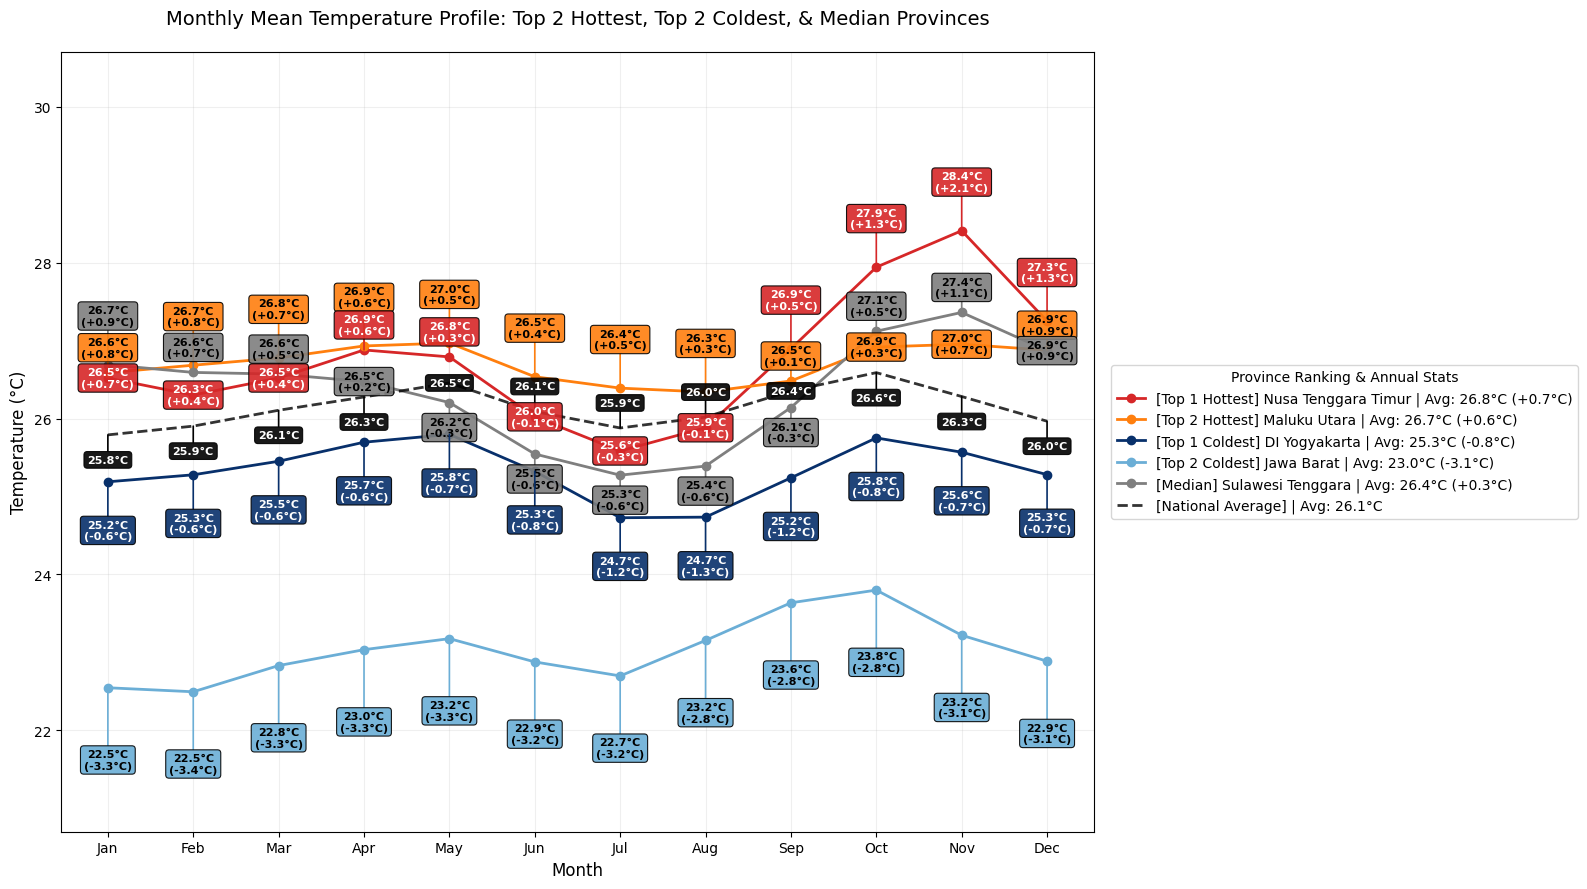

In [46]:
import os
print(os.getcwd())

g:\Data Analyst\Indonesia Weather


> Notes for Streamlit

---
### Climate Scenario Modeling & Domain-Driven Sensitivity Analysis

To overcome the inherent inability of tree-based ensemble models (such as CatBoost and XGBoost) to extrapolate linear temporal trends beyond historical boundaries, a domain-driven heuristic perturbation strategy (*Scenario-based Stress Testing*) was established. The perturbation parameters applied to future projections are grounded in official climate monitoring reports and peer-reviewed atmospheric studies:

#### 1. Long-Term Surface Temperature Trend (+0.03 °C / Year)
* **Scientific Rationale:** Meteorological observation records across Indonesia between 1981 and 2020 indicate an average surface warming rate of approximately **0.2 °C to 0.3 °C per decade** (~0.02 °C – 0.03 °C per year), with urbanized and low-elevation stations (e.g., Jakarta, Surabaya, and Medan) experiencing warming trends up to **0.035 °C – 0.04 °C per year** due to combined greenhouse forcing and Urban Heat Island (UHI) effects.
* **Implementation:** An annual linear increment of $+0.03 ^\circ\text{C}$ is applied to post-2026 baseline projections to represent realistic climate warming trajectories.
* **Official Reference:** 
  * [BMKG — Analisis Iklim dan Tren Suhu Permukaan Indonesia](https://www.bmkg.go.id/iklim/)
  * [Bappenas & BMKG — Kajian Kebijakan Perubahan Iklim Indonesia](https://lcdi-indonesia.id/)

---

#### 2. Rainfall Deficit Under Moderate–Strong El Niño (-40%)
* **Scientific Rationale:** During positive phases of the El Niño–Southern Oscillation (ENSO) where the Oceanic Niño Index (ONI) exceeds $+1.5 ^\circ\text{C}$, the convective branch of the Walker Circulation shifts eastward. This produces strong atmospheric subsidence across the Indonesian Maritime Continent, driving rainfall anomalies between **-30% and -50%** below climatological baselines in monsoonal regions (Java, Bali, Nusa Tenggara, southern Kalimantan, and South Sulawesi). A central value of **-40%** represents a realistic strong dry-spell scenario.
* **Peer-Reviewed References:**
  * [Aldrian, E., & Susanto, R. D. (2003). *Identification of three dominant rainfall regions within Indonesia and their relationship to ENSO*. International Journal of Climatology, 23(12), 1435–1452](https://doi.org/10.1002/joc.950)
  * [Hendon, H. H. (2003). *Indonesian Rainfall Variability: Impacts of ENSO and Local SST*. Journal of Climate, 16(11), 1775–1790](https://doi.org/10.1175/1520-0442(2003)016%3C1775:IRVIOE%3E2.0.CO;2)

---

#### 3. Shortwave Solar Radiation Increase (+15%)
* **Scientific Rationale:** The thermodynamic consequence of El Niño-induced subsidence is a substantial reduction in convective cloud cover (cloud fraction diminishes by 20%–30%). Under reduced optical cloud thickness and clear-sky dry spells, downwelling surface shortwave radiation (`shortwave_radiation_sum`) increases by **10% to 20%** above normal wet-monsoon levels. A **+15%** perturbation reflects these high-insolation conditions.
* **Peer-Reviewed Reference:**
  * [IPCC Sixth Assessment Report (AR6) — Working Group I: The Physical Science Basis (Chapter 7: Energy Budget and Radiative Forcing)](https://www.ipcc.ch/report/ar6/wg1/chapter/chapter-7/)
  * [NOAA Climate.gov — ENSO Climate Impacts and Radiation Feedback](https://www.climate.gov/enso)

---

#### 4. Wet Anomaly Under La Niña Scenarios (+20% to +40% Precipitation)
* **Scientific Rationale:** Conversely, during La Niña events, anomalous sea surface warmth around the Indonesian archipelago enhances deep tropical convection. BMKG historical records confirm widespread monthly rainfall surges of **+20% to +40%** above normal, coupled with extended precipitation hours and reduced downward shortwave radiation due to cloud albedo cooling.
* **Peer-Reviewed Reference:**
  * [As-syakur, A. R., et al. (2014). *High-resolution rainfall patterns during ENSO events in Indonesia*. Atmospheric Research, 147–148, 158–168](https://doi.org/10.1016/j.atmosres.2014.05.018)
  * [BMKG — Monitoring Dinamika Atmosfer dan Perkembangan Fenomena La Niña](https://www.bmkg.go.id/iklim/indeks-enso.bmkg)

#### 5. Direct Thermodynamic Temperature Offset (+0.8 °C / -0.5 °C)
* **Scientific Rationale:** During strong El Niño phases, atmospheric subsidence and reduced cloud cover lead to significant surface warming. BMKG observations confirm that positive temperature anomalies can reach up to **+0.8 °C** during peak El Niño months compared to the 1991–2020 climatology baseline. Conversely, during La Niña, increased convective cloud cover and evaporative cooling reduce surface temperatures, with BMKG Climate Outlooks frequently projecting monthly temperature anomalies dropping by **-0.5 °C** to **-0.1 °C**. Furthermore, spatial studies on Land Surface Temperature (LST) confirm that ENSO phases strongly dictate localized temperature anomalies across Indonesian cities.
* **Implementation:** A direct fixed offset of **+0.8 °C** is added to El Niño temperature predictions, while **-0.5 °C** is subtracted from La Niña predictions. This step explicitly forces the final output to bypass the tree-based model's saturation limit at historical maximums/minimums.
* **Official & Peer-Reviewed References:**
  * [BMKG — Analisis Anomali Suhu Udara Rata-Rata (Periode Normal 1991-2020)](https://www.bmkg.go.id/iklim/anomali-suhu-udara)
  * [BMKG — Climate Outlook: Prediksi Anomali Suhu dan Curah Hujan](https://www.bmkg.go.id/iklim/climate-outlook-2025)
  * [Imroah, F. F. K., & Setiawan, N. (2024). *Integration of Landsat-8 OLI/TIRS and Sentinel-1A PolSAR for analyzing land surface temperature and its anomalies linked to ENSO in Surakarta, Indonesia*. Geomatica, 76(2), 100038](https://www.researchgate.net/publication/386150855_Integration_of_Landsat-8_OLITIRS_and_Sentinel-1A_PolSAR_for_Analyzing_Land_Surface_Temperature_and_its_Anomalies_Linked_to_ENSO_in_Surakarta_Indonesia)

---

#### Methodological Value: Applied ML Sensitivity Analysis
By integrating these physics-guided parameters into the Streamlit deployment interface:
1. **Compensating Extrapolation Limits:** Prevents decision-tree algorithms from generating flat, static multi-year projections.
2. **Decision Support Utility:** Allows stakeholders at meteorological agencies to evaluate temperature distributions across varied ENSO phases (*Neutral*, *Strong El Niño*, and *La Niña*) rather than relying strictly on unperturbed static historical averages.
---

> ### Save dataset into .gz, so we can upload into github repo

In [1]:
import pandas as pd
df = pd.read_csv('idn_weather_daily.csv')
df.to_csv('idn_weather_daily.csv.gz', index=False, compression='gzip')